# 제7교시. Dense와 MoE: 어떤 FFN을 사용할까?


## 이번 교시의 목표

- Dense와 MoE의 FFN 경로를 구별합니다.
- 전문가 선택과 출력 가중합을 설명합니다.
- 전문가 저장량과 토큰당 선택량을 구별합니다.


## 이번 교시 핵심 용어

- **순전파 신경망(feed-forward network, FFN)**: 각 토큰 위치의 표현을 변환하는 신경망이며 위치 간 정보를 읽는 어텐션과 구별합니다.
- **밀집형 FFN(dense FFN)**: 각 토큰이 해당 층의 같은 FFN 가중치 경로를 사용하는 방식입니다.
- **전문가 혼합(mixture of experts, MoE)**: 여러 FFN 전문가 후보 중 토큰별로 일부를 선택하는 구조입니다.
- **라우터(router)**: 토큰 표현을 바탕으로 사용할 전문가와 혼합 가중치를 정하는 모듈입니다.
- **상위 k개 선택(top-k selection)**: 점수가 높은 후보 k개와 그 번호를 고르는 연산입니다.

## 실습 준비

프로젝트 커널에서 차례로 실행하세요. 필요한 공식 설정은 Notebook에 포함되어 있고 구현은 이미 설치된 Transformers에서 읽습니다. 새 다운로드·패키지·GPU 연산은 필요 없습니다.

**열기와 실행:** VS Code에서 이 `.ipynb`를 열고 오른쪽 위 커널 선택에서 제1교시에 준비한 프로젝트 가상환경의 Python을 선택합니다. 그림과 필요한 설정은 노트북에 내장되어 있으므로 별도 가이드북이나 그림 파일을 열 필요가 없습니다. 제1교시에서 준비한 `transformers==5.23.0`과 그 의존 패키지가 필요합니다. 가중치를 다운로드하거나 학습·추론하지 않으며 설치된 라이브러리의 소스와 설정만 읽습니다.

**진행과 문제 확인:** 위에서부터 개념·그림·코드 설명을 확인하고 해당 코드 셀을 실행한 뒤 바로 아래 출력 설명과 대조합니다. 앞 셀의 변수와 함수를 다음 셀이 사용하므로 중간부터 실행하지 않습니다. 오류가 나면 이후 셀을 진행하지 말고 오류 전문과 마지막 성공 셀을 보존하세요. `NameError`는 앞 셀 실행 여부, `ModuleNotFoundError`는 선택한 커널과 제1교시 준비 상태, `AssertionError`는 바로 위 검사 조건과 출력값을 확인합니다. 버전이나 커널을 바꾼 뒤에는 처음부터 다시 실행하고 실행 출력이 포함된 노트북을 저장합니다. PASS는 각 셀에 적힌 검사 범위만을 뜻합니다.

제6교시와 같은 **실제 gpt-oss-20b 공식 설정**에서 전문가 수와 선택 수를 읽고, 설치된 실제 라우터·전문가 구현을 분석합니다. 제4교시 SmolLM2의 Dense FFN과 구분합니다. 오늘은 대형 모델의 가중치·router 점수·실제 토큰 배정을 실행하지 않는 **설정·소스 분석 실습**입니다. 임의의 라우터 점수나 축소 모델을 실제 모델 결과처럼 보여 주지 않습니다.


## 1. Dense와 MoE를 구분하기
Dense FFN은 토큰마다 같은 학습된 FFN을 사용합니다. MoE는 라우터가 토큰 표현을 보고 여러 FFN 전문가 중 일부를 고릅니다. 전문가라는 이름이 사람처럼 고정된 직업·주제 전문성이 있다는 보장은 아닙니다. 학습 결과에 따라 배정이 달라질 수 있습니다.

어텐션은 ‘어느 토큰 위치를 참고하는가’, FFN 라우팅은 ‘어느 전문가 계산을 적용하는가’입니다. 슬라이딩 윈도우/전체 범위 어텐션과 Dense/MoE는 독립적인 설계 축입니다.

아래 그림의 A·B는 두 토큰 위치의 벡터 표현이며, 전문가 네 개 중 두 개를 고르는 구조는 이해를 위한 예시입니다. 실제 gpt-oss-20b의 설정은 32개 중 4개입니다.

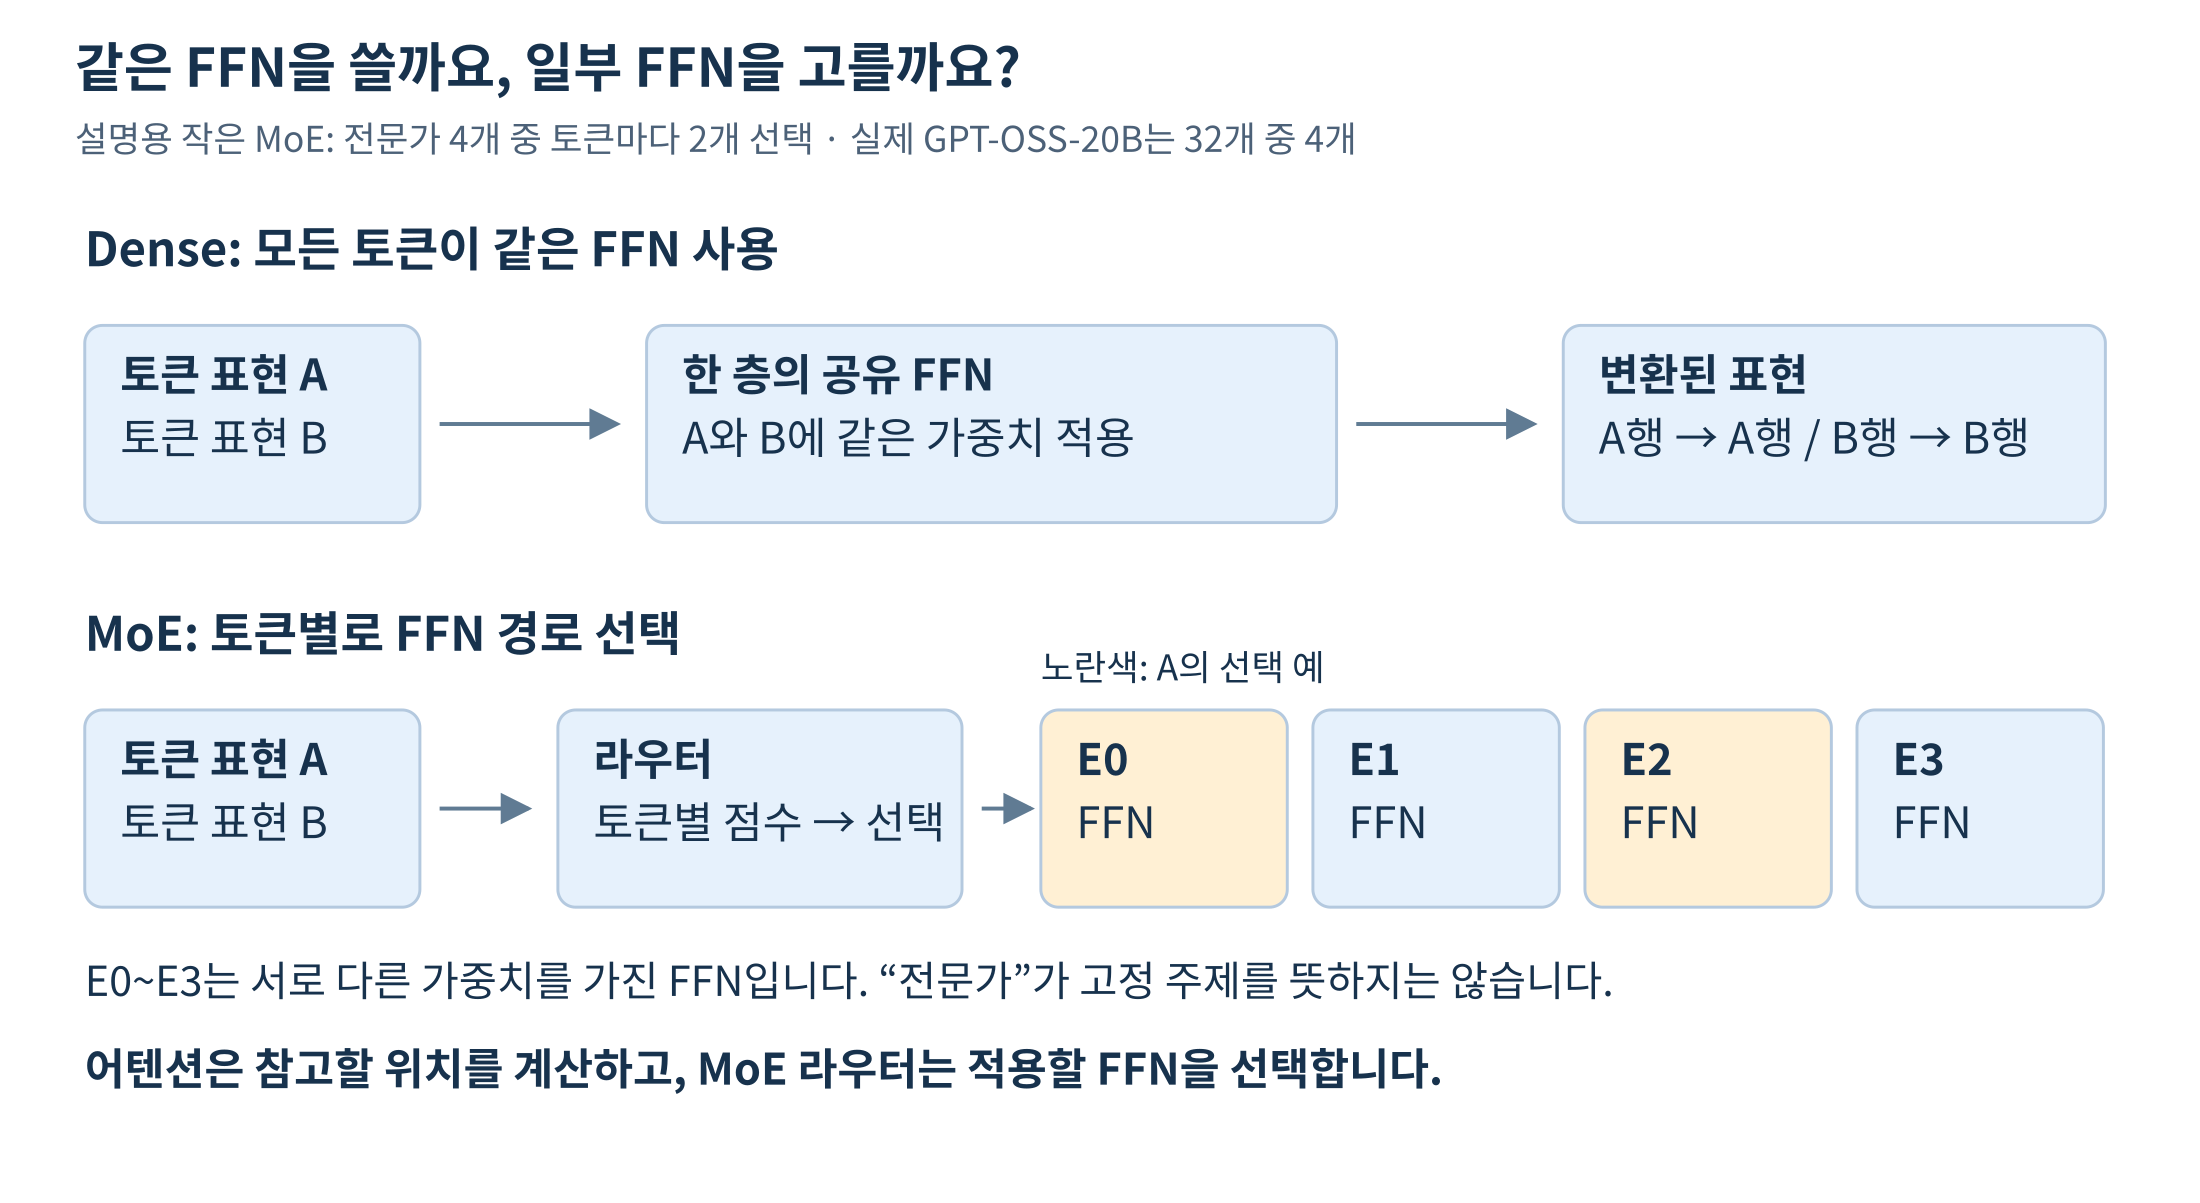

**그림 설명:** 같은 FFN을 써도 입력 표현이 다르면 출력은 달라집니다. 아래 개념 연결에서 설명용 A·B의 선택을 따라가며, 실제 GPT-OSS 설정 32개 중 4개와 구별하세요.



### 개념 연결: 네 작업대 중 두 곳을 거치는 토큰

**FFN을 토큰 표현을 가공하는 작업대라고 생각해 보세요.** 작업대에 들어가는 것은 문장 전체나 글자 자체가 아니라, 한 토큰 위치를 나타내는 숫자 벡터입니다. 같은 층의 Dense FFN에서는 토큰 A와 B가 모두 같은 작업대를 거칩니다. 같은 가중치를 쓰더라도 입력 벡터가 다르면 출력은 달라집니다. ‘같은 FFN’은 ‘같은 답’을 뜻하지 않습니다.

MoE에는 서로 다른 가중치를 가진 작업대가 여러 개 있습니다. 이 교시의 **설명용 예시**에서는 전문가 E0·E1·E2·E3 네 개 중 토큰마다 두 개를 선택한다고 하겠습니다. A는 E0·E2, B는 E1·E2로 보낼 수 있습니다. E2는 두 토큰이 함께 사용하는 전문가가 되지만, 각 토큰의 표현은 따로 처리합니다. A·B는 단어 종류가 아니라 두 토큰 위치의 표현을 가리키며, 이 배정은 실제 모델에서 관측한 결과가 아닙니다.

**누가 작업대를 고를까요?** 전문가 FFN과 별도인 라우터가 **전문가를 실행하기 전에** 같은 입력 토큰 표현에 후보별 가중치와 편향을 적용하여 점수를 계산합니다. 점수가 높은 두 곳을 고르고 각 출력을 반영할 비율도 정합니다. 계산 순서는 구조로 정하며 가중치·편향의 숫자는 학습하고, 추론에서는 고정해 사용합니다. 전문가는 완성 문장을 써서 투표하지 않으며 ‘수학 담당’, ‘문법 담당’처럼 미리 정한 직업도 아닙니다. 구체적인 점수 계산은 2절에서 한 번에 따라갑니다.

왜 네 곳을 모두 계산하지 않을까요? 한 토큰이 거칠 전문가 수는 제한하면서 서로 다른 가중치의 후보를 더 많이 마련하려는 설계입니다. 다만 A가 두 곳만 거쳤다고 다른 두 작업대의 설계도를 버릴 수는 없습니다. 뒤의 B가 다른 곳을 사용할 수 있기 때문입니다. **토큰당 계산 경로를 고르는 것과 전체 후보 가중치를 보관하는 것은 다릅니다.**

이후 이 예시로 선택 → 가중합 → 저장량의 차이를 따라갑니다. **실제 분석 대상 gpt-oss-20b는 네 개 중 두 개가 아니라, 한 MoE 층에서 32개 중 4개를 고릅니다.** 실습 코드는 그 설정과 소스를 읽을 뿐 A·B의 라우팅이나 전문가 계산을 실행하지 않습니다.


### Dense와 MoE를 실제 설정으로 비교하기
이 셀은 gpt-oss-20b와 Dense 비교용 SmolLM2의 고정 설정 원본을 복원하고 SHA256을 검사합니다. **Dense FFN**은 각 토큰이 해당 층의 같은 FFN을 통과하는 방식입니다. **MoE(Mixture of Experts)**는 여러 FFN 후보를 두고 라우터가 토큰별로 일부를 선택하는 방식입니다. 여기서 전문가는 별도의 완성된 언어 모델이 아니라 블록 내부의 FFN입니다.

`hidden_size`는 토큰 표현의 폭이고 `intermediate_size`는 FFN 내부 계산 폭입니다. 출력의 Dense `576 / 1536`과 MoE 전문가 `32 / 4`를 구별하세요. 후자는 이 모델의 MoE 층에 전문가 후보 32개가 있고 토큰마다 4개를 고른다는 뜻입니다.

`[PASS] 실제 Dense·MoE 설정과 원본 해시`는 자료와 설정 확인입니다. 가중치를 로드하지 않아 CUDA 연산은 필요하지 않으며, 서로 크기가 다른 두 모델의 품질이나 속도를 비교한 실험은 아닙니다.

### 코드 설명: 같은 절차로 두 설정을 준비하기

Dense와 MoE의 고정 설정을 같은 절차로 읽습니다. 표현 폭과 전문가 수는 서로 다른 비교 축이며, 이 셀은 원본 확인과 설계값 분석까지만 수행합니다.

두 모델 모두 먼저 설정 파일의 지문을 검증한 뒤 필요한 항목을 꺼냅니다. 이어지는 절에서 Dense와 전문가 혼합(MoE)을 비교할 때, 이 셀의 값은 실제 계산 결과가 아니라 구성의 기준점이 됩니다.


In [1]:
import json, hashlib, base64, platform, sys, ast
from pathlib import Path
from collections import Counter
import transformers
from transformers import GptOssConfig, DynamicCache
# 운영체제 조건만 검사하며 CUDA 사용이나 GPU 추론 여부를 검사하지 않습니다.
assert platform.system() == "Windows", "Windows 11 교육 환경을 사용하세요."
print("Python:", sys.version.split()[0], "transformers:", transformers.__version__)
# 공식 고정 revision config.json의 원본 바이트입니다. 수정할 필요가 없습니다.
CONFIG_BASE64 = 'ewogICJhcmNoaXRlY3R1cmVzIjogWwogICAgIkdwdE9zc0ZvckNhdXNhbExNIgogIF0sCiAgImF0dGVudGlvbl9iaWFzIjogdHJ1ZSwKICAiYXR0ZW50aW9uX2Ryb3BvdXQiOiAwLjAsCiAgImVvc190b2tlbl9pZCI6IDIwMDAwMiwKICAiZXhwZXJ0c19wZXJfdG9rZW4iOiA0LAogICJoZWFkX2RpbSI6IDY0LAogICJoaWRkZW5fYWN0IjogInNpbHUiLAogICJoaWRkZW5fc2l6ZSI6IDI4ODAsCiAgImluaXRpYWxfY29udGV4dF9sZW5ndGgiOiA0MDk2LAogICJpbml0aWFsaXplcl9yYW5nZSI6IDAuMDIsCiAgImludGVybWVkaWF0ZV9zaXplIjogMjg4MCwKICAibGF5ZXJfdHlwZXMiOiBbCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIsCiAgICAic2xpZGluZ19hdHRlbnRpb24iLAogICAgImZ1bGxfYXR0ZW50aW9uIiwKICAgICJzbGlkaW5nX2F0dGVudGlvbiIsCiAgICAiZnVsbF9hdHRlbnRpb24iLAogICAgInNsaWRpbmdfYXR0ZW50aW9uIiwKICAgICJmdWxsX2F0dGVudGlvbiIKICBdLAogICJtYXhfcG9zaXRpb25fZW1iZWRkaW5ncyI6IDEzMTA3MiwKICAibW9kZWxfdHlwZSI6ICJncHRfb3NzIiwKICAibnVtX2F0dGVudGlvbl9oZWFkcyI6IDY0LAogICJudW1fZXhwZXJ0c19wZXJfdG9rIjogNCwKICAibnVtX2hpZGRlbl9sYXllcnMiOiAyNCwKICAibnVtX2tleV92YWx1ZV9oZWFkcyI6IDgsCiAgIm51bV9sb2NhbF9leHBlcnRzIjogMzIsCiAgIm91dHB1dF9yb3V0ZXJfbG9naXRzIjogZmFsc2UsCiAgInBhZF90b2tlbl9pZCI6IDE5OTk5OSwKICAicXVhbnRpemF0aW9uX2NvbmZpZyI6IHsKICAgICJtb2R1bGVzX3RvX25vdF9jb252ZXJ0IjogWwogICAgICAibW9kZWwubGF5ZXJzLiouc2VsZl9hdHRuIiwKICAgICAgIm1vZGVsLmxheWVycy4qLm1scC5yb3V0ZXIiLAogICAgICAibW9kZWwuZW1iZWRfdG9rZW5zIiwKICAgICAgImxtX2hlYWQiCiAgICBdLAogICAgInF1YW50X21ldGhvZCI6ICJteGZwNCIKICB9LAogICJybXNfbm9ybV9lcHMiOiAxZS0wNSwKICAicm9wZV9zY2FsaW5nIjogewogICAgImJldGFfZmFzdCI6IDMyLjAsCiAgICAiYmV0YV9zbG93IjogMS4wLAogICAgImZhY3RvciI6IDMyLjAsCiAgICAib3JpZ2luYWxfbWF4X3Bvc2l0aW9uX2VtYmVkZGluZ3MiOiA0MDk2LAogICAgInJvcGVfdHlwZSI6ICJ5YXJuIiwKICAgICJ0cnVuY2F0ZSI6IGZhbHNlCiAgfSwKICAicm9wZV90aGV0YSI6IDE1MDAwMCwKICAicm91dGVyX2F1eF9sb3NzX2NvZWYiOiAwLjksCiAgInNsaWRpbmdfd2luZG93IjogMTI4LAogICJzd2lnbHVfbGltaXQiOiA3LjAsCiAgInRpZV93b3JkX2VtYmVkZGluZ3MiOiBmYWxzZSwKICAidHJhbnNmb3JtZXJzX3ZlcnNpb24iOiAiNC41NS4wLmRldjAiLAogICJ1c2VfY2FjaGUiOiB0cnVlLAogICJ2b2NhYl9zaXplIjogMjAxMDg4Cn0K'
# GPT-OSS 원본 바이트를 복원하고 SHA256으로 고정 설정과의 일치를 검사합니다.
raw = base64.b64decode(CONFIG_BASE64)
assert hashlib.sha256(raw).hexdigest() == '3a2a26ded679375b7928ddeca59764df7cea83220c1961035f6d6e232659e9ce'
# raw는 JSON 파일의 바이트이고 config_data는 필드명→값 사전입니다. 해시 일치와 모델 성능은 별개입니다.
config_data = json.loads(raw)
# 설정 객체만 생성합니다. 학습 가중치나 전문가 텐서는 로드하지 않습니다.
# **는 사전의 키를 생성자의 매개변수 이름으로 전달합니다. 설정 객체에는 학습된 행렬이 없습니다.
config = GptOssConfig(**config_data)
print("Model:", config_data["architectures"])
print("Source revision: 6cee5e81ee83917806bbde320786a8fb61efebee")
print("Config SHA256:", hashlib.sha256(raw).hexdigest())
print("Scope: configuration/source inspection only; no checkpoint weights or inference")
DENSE_CONFIG_BASE64 = 'ewogICJhcmNoaXRlY3R1cmVzIjogWwogICAgIkxsYW1hRm9yQ2F1c2FsTE0iCiAgXSwKICAiYXR0ZW50aW9uX2JpYXMiOiBmYWxzZSwKICAiYXR0ZW50aW9uX2Ryb3BvdXQiOiAwLjAsCiAgImJvc190b2tlbl9pZCI6IDAsCiAgImVvc190b2tlbl9pZCI6IDAsCiAgImhpZGRlbl9hY3QiOiAic2lsdSIsCiAgImhpZGRlbl9zaXplIjogNTc2LAogICJpbml0aWFsaXplcl9yYW5nZSI6IDAuMDQxNjY2NjY2NjY2NjY2NjY0LAogICJpbnRlcm1lZGlhdGVfc2l6ZSI6IDE1MzYsCiAgImlzX2xsYW1hX2NvbmZpZyI6IHRydWUsCiAgIm1heF9wb3NpdGlvbl9lbWJlZGRpbmdzIjogODE5MiwKICAibW9kZWxfdHlwZSI6ICJsbGFtYSIsCiAgIm51bV9hdHRlbnRpb25faGVhZHMiOiA5LAogICJudW1faGlkZGVuX2xheWVycyI6IDMwLAogICJudW1fa2V5X3ZhbHVlX2hlYWRzIjogMywKICAicHJldHJhaW5pbmdfdHAiOiAxLAogICJybXNfbm9ybV9lcHMiOiAxZS0wNSwKICAicm9wZV9pbnRlcmxlYXZlZCI6IGZhbHNlLAogICJyb3BlX3NjYWxpbmciOiBudWxsLAogICJyb3BlX3RoZXRhIjogMTAwMDAwLAogICJ0aWVfd29yZF9lbWJlZGRpbmdzIjogdHJ1ZSwKICAidG9yY2hfZHR5cGUiOiAiYmZsb2F0MTYiLAogICJ0cmFuc2Zvcm1lcnNfdmVyc2lvbiI6ICI0LjQwLjEiLAogICJ1c2VfY2FjaGUiOiB0cnVlLAogICJ2b2NhYl9zaXplIjogNDkxNTIKfQo='
# Dense 비교 모델도 별도의 원본과 기준 해시로 확인합니다.
dense_raw = base64.b64decode(DENSE_CONFIG_BASE64)
assert hashlib.sha256(dense_raw).hexdigest() == '1d556eab73b69c7f11f64c557a2f9c6f440bd4c6b89bb2584a6b498c92603843'
# Dense 설정은 사전으로 읽습니다. hidden/intermediate는 표현 폭이지 전문가 수가 아닙니다.
# hidden_size는 FFN 입출력 폭, intermediate_size는 중간 확장 폭입니다. 둘의 크기로 전문가 수를 판단하지 않습니다.
dense = json.loads(dense_raw)
print("Dense reference:", dense["architectures"], "hidden/intermediate:", dense["hidden_size"], dense["intermediate_size"])
# MoE 후보 32개와 토큰당 선택 4개를 검사합니다. 실제 라우팅은 실행하지 않습니다.
assert config.num_local_experts == 32 and config.num_experts_per_tok == 4
print("MoE experts / selected per token:", config.num_local_experts, config.num_experts_per_tok)
print("[PASS] 실제 Dense·MoE 설정과 원본 해시")

%USERPROFILE%\AI-Engineering\python31210-signed-qa-20261117\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.10 transformers: 5.23.0
Model: ['GptOssForCausalLM']
Source revision: 6cee5e81ee83917806bbde320786a8fb61efebee
Config SHA256: 3a2a26ded679375b7928ddeca59764df7cea83220c1961035f6d6e232659e9ce
Scope: configuration/source inspection only; no checkpoint weights or inference
Dense reference: ['LlamaForCausalLM'] hidden/intermediate: 576 1536
MoE experts / selected per token: 32 4
[PASS] 실제 Dense·MoE 설정과 원본 해시


### 출력 설명: 표현 폭과 전문가 수를 같은 숫자 축으로 비교하지 않습니다

Dense 비교 모델의 `hidden/intermediate: 576 1536`은 **토큰 표현 폭 576 → FFN 내부 폭 1536**을 뜻합니다. `LlamaForCausalLM`은 이 모델이 사용하는 구현 클래스 계열 이름이며, 여기서 별도의 Meta Llama 체크포인트를 불러온 것은 아닙니다.

GPT-OSS의 `experts / selected per token: 32 4`는 **한 MoE 층에 전문가 후보 32개, 토큰당 선택 4개**라는 뜻입니다. 앞의 576·1536처럼 벡터 폭을 나타내는 수가 아닙니다. 4개를 선택해도 다른 토큰에 쓰일 나머지 전문가 가중치를 없애는 것은 아닙니다.

revision과 SHA256은 읽은 GPT-OSS 설정의 버전·내용 식별 정보입니다. 끝의 PASS는 두 설정의 원본 해시와 전문가 수 조건이 맞았음을 뜻합니다. `Scope`에 적힌 대로 모델 가중치·토큰별 라우팅을 실행하지 않았으므로 이 출력으로 실제 전문가 번호나 품질을 판단할 수는 없습니다.

환경 표시는 **Python 3.12.10 / Transformers 5.23.0**입니다. 이 버전은 뒤에서 읽는 설치 소스의 기준이며, 모델 정확도나 속도 수치가 아닙니다.

## 2. 실제 구현의 라우터 동작 확인

### 점수 계산식은 설계하고, 그 안의 수치는 학습합니다

**라우터가 전문가의 답을 미리 비교하는 것은 아닙니다.** 전문가 FFN을 실행하기 전에, 같은 입력 토큰 표현을 라우터의 선형 변환에 넣어 후보별 점수를 먼저 만듭니다. 구조를 설계할 때는 ‘입력 표현 → 선형 점수 → top-k → 선택한 점수의 softmax’라는 계산 순서와 후보 수·선택 수를 정합니다. 반면 선형 변환 안의 **가중치(weight)와 편향(bias)의 숫자**는 학습으로 정해집니다.

언어 모델을 학습할 때 다음 토큰을 잘 예측하도록 손실을 줄이는 과정에서 라우터와 전문가의 파라미터도 학습됩니다. 사람이 매 토큰에 ‘정답 전문가는 E2’라는 번호나 ‘E0은 수학 담당’이라는 분야 표지를 붙여 가르친다는 뜻이 아닙니다. 학습 설계에 따라 전문가 사용 균형 등을 위한 보조 목적을 함께 둘 수 있지만, 여기서는 그런 학습을 수행하거나 전문가별 의미를 검증하지 않습니다.

학습이 끝나 **일반적인 추론을 할 때는 저장된 가중치와 편향을 고정하여 사용**합니다. 입력마다 점수가 달라지는 이유는 그때마다 가중치를 새로 배우기 때문이 아니라 입력 표현이 달라지기 때문입니다. 같은 단어라도 문맥과 층에 따라 표현이 달라질 수 있으므로, 단어마다 고정 전문가 번호가 붙는 구조로 생각하지 마세요.

### 같은 입력에서 어떻게 서로 다른 네 점수가 나올까요?

계산을 손으로 따라가기 위한 **설명용 예시**로 입력 A를 `[2, 1]`이라고 놓겠습니다. 입력을 행 벡터 `x`로 쓰면 라우터의 선형 변환은 `logits = x Wᵀ + b`입니다. 실제 코드의 `F.linear`가 하는 일에 대응합니다. 여기서 `W`의 **각 행은 전문가 하나의 점수를 만드는 라우터 가중치**이며 전문가 FFN 자체의 가중치가 아닙니다.

설명용 W의 네 행을 `[1, 0]`, `[0, -1]`, `[0, 2]`, `[-1, 1]`, 편향 b를 `[0, 1, -1, 0]`으로 정하면 다음과 같습니다. 이 값들은 원리를 설명하기 위해 정한 숫자이며 실제 GPT-OSS의 학습된 가중치가 아닙니다.

| 점수를 낼 후보 | 라우터 W의 해당 행 | 편향 | 같은 입력 A = [2, 1]에 대한 계산 | 점수 |
|---|---|---:|---|---:|
| E0 | [1, 0] | 0 | 2×1 + 1×0 + 0 | 2 |
| E1 | [0, −1] | 1 | 2×0 + 1×(−1) + 1 | 0 |
| E2 | [0, 2] | −1 | 2×0 + 1×2 − 1 | 1 |
| E3 | [−1, 1] | 0 | 2×(−1) + 1×1 + 0 | −1 |

**입력은 하나로 같고, 적용하는 가중치 행과 편향이 다르므로 네 점수가 나옵니다.** 이 단계에서는 E0·E1·E2·E3의 FFN을 아직 실행하지 않았습니다. 출력 `[2, 0, 1, -1]`은 정규화 전 점수인 **로짓(logit)**이며 확률이 아니므로 합이 1일 필요가 없습니다.

### 점수에서 선택 번호와 혼합 비율로 넘어갑니다

1. **상위 두 개 선택:** 설명용 `top-k`에서 k=2라면 점수가 큰 E0·E2를 고릅니다. 선택 번호 `[0, 2]`와 선택 점수 `[2, 1]`는 서로 다른 정보입니다.
2. **선택한 점수만 정규화:** `[2, 1]`에 softmax를 적용하면 `e²/(e²+e¹) ≈ 0.731`, `e¹/(e²+e¹) ≈ 0.269`입니다. 선택된 두 전문가 출력의 반영 비율이며 합이 1입니다. 전체 네 점수를 먼저 정규화하는 순서가 아닙니다.
3. **선택된 전문가 FFN 실행:** E0·E2에 A를 보내 각각 변환하고, 다음 절에서 두 결과를 위 비율로 합칩니다. 선택되지 않은 E1·E3은 이 토큰의 전문가 출력 합에 참여하지 않습니다.

0.731은 ‘다음 토큰의 정답 확률’이나 ‘E0의 정확도’가 아닙니다. **이 토큰에서 선택된 전문가 출력을 얼마나 반영할지** 나타내는 값입니다.

**실제 설정으로 돌아오면**, gpt-oss-20b의 입력 표현 폭은 2가 아니라 **2,880**, 전문가 후보는 4가 아니라 **32**, 선택 수는 2가 아니라 **4**입니다. 라우터 W의 shape는 `(32, 2880)`, 편향은 `(32,)`이며, 입력 토큰 하나의 2,880개 성분을 32개 점수로 바꾼 뒤 top-4를 고릅니다. 여러 토큰이라면 각 토큰 행에 같은 라우터를 적용합니다. 이 설명은 설정과 소스의 형상을 연결한 것이며 실제 가중치나 점수를 읽어 관측한 결과가 아닙니다.

아래에서는 `GptOssTopKRouter.forward`의 소스 문자열을 찾아 계산 순서를 확인합니다. **공식 설정·소스를 읽는 실습**과 **위의 설명용 손계산**을 구별하세요. 함수를 출력할 뿐 실제 입력으로 호출하거나 학습하지 않습니다.

![토큰 A의 표현 [2,1]에 라우터의 네 가중치 행과 편향을 적용하여 점수 [2,0,1,-1]을 얻고 E0,E2를 선택한 뒤 비율을 계산합니다.](attachment:lesson07-router-topk.png)

**그림 설명:** W의 행은 [1,0], [0,−1], [0,2], [−1,1], 편향은 [0,1,−1,0]인 설명용 예입니다. 실제 라우터의 W와 b는 학습하며 추론 때 고정됩니다. 점수 계산과 전문가 FFN 실행은 별도 단계입니다.

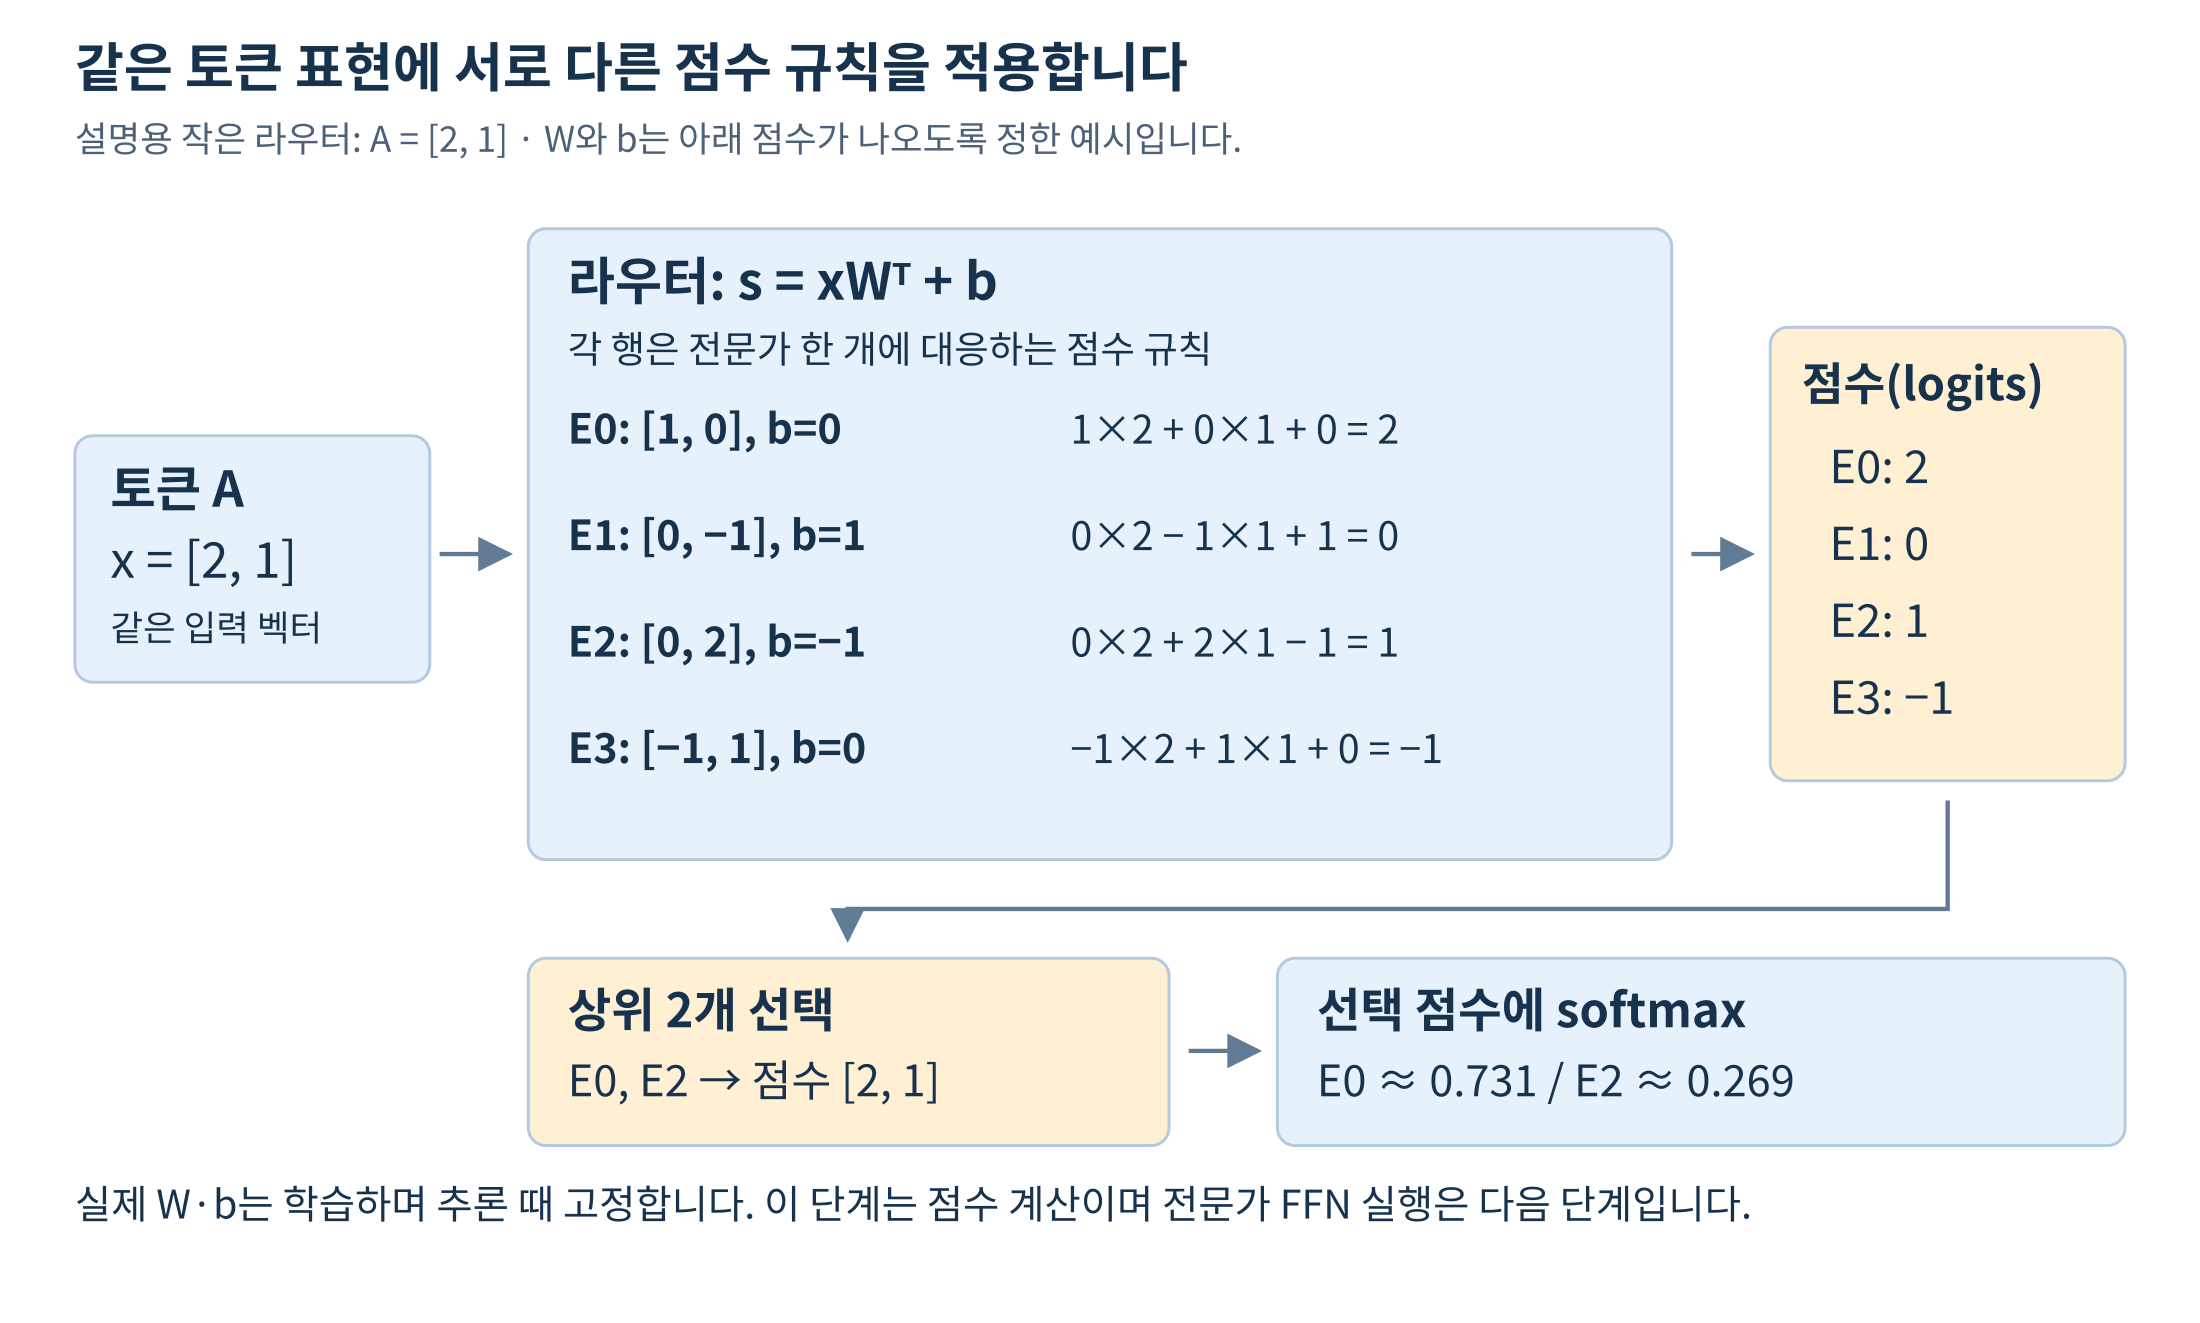

### 라우터 소스를 읽기 위한 연결

`ast.parse`로 설치된 파일의 문법 구조를 읽고 `GptOssTopKRouter.forward` 원문을 추출합니다. 반환 이름 중 `router_logits`는 전체 후보 점수, `router_indices`는 선택 번호, `router_scores`는 선택된 출력의 혼합 가중치입니다. 설명용 A의 `[2,0,1,-1]`, `[0,2]`, 약 `[0.731,0.269]`를 각각 이 역할에 연결하되 실제 값으로 혼동하지 마세요.

아래 자동 검사는 추출한 함수에 `torch.topk`와 `softmax(router_top_value` 두 문구가 들어 있는지 확인합니다. 점수 → top-k → 선택 후 softmax의 전체 순서는 출력된 원문에서 직접 읽습니다. 실제 선택 번호나 확률은 생성하지 않습니다.


### 코드 설명: 소스 속 텐서 shape를 해석하되 실행과 구분하기

설치된 라우터의 함수 원문을 찾아 점수 계산·상위 후보 선택·선택 후 정규화 순서를 읽습니다. 원문의 shape는 계산 구조를 설명하며 실제 입력을 넣어 관측한 텐서가 아닙니다.

눈여겨볼 순서는 전체 전문가 점수 계산 → 토큰마다 상위 전문가 선택 → 선택된 점수만 소프트맥스로 정규화입니다. 이 순서는 출력된 함수 원문을 따라 확인합니다. 자동 검사로 전체 순서를 판정하거나 어느 전문가가 선택되는지 측정하지는 않습니다.


In [2]:
base = Path(transformers.__file__).parent
source = (base / "models/gpt_oss/modeling_gpt_oss.py").read_text(encoding="utf-8")
# 원문을 실행하지 않고 문법 트리로 바꿉니다.
tree = ast.parse(source)
# 이름이 맞는 클래스 정의의 첫 노드를 찾습니다. 없으면 next에서 중단됩니다.
def class_node(name):
    return next(n for n in tree.body if isinstance(n, ast.ClassDef) and n.name == name)
# 클래스 내부 함수 정의를 찾고 그 범위의 소스 문자열을 반환합니다.
def method_text(class_name, method_name):
    node = next(n for n in class_node(class_name).body if isinstance(n, ast.FunctionDef) and n.name == method_name)
    return ast.get_source_segment(source, node)
# 함수 소스를 추출할 뿐 실제 토큰에 대한 라우터 forward를 실행하지 않습니다.
# 소스의 점수 축은 (토큰 수, 후보 32개), 선택 후 축은 (토큰 수, 선택 4개)입니다. 실제 텐서 생성은 하지 않습니다.
router_source = method_text("GptOssTopKRouter", "forward")
# 전체 점수 → top-k → 선택된 점수의 softmax라는 호출 문구를 검사합니다.
assert "torch.topk" in router_source and "softmax(router_top_value" in router_source
# 출력은 함수 원문입니다. 주석의 토큰/전문가 축은 이번 실행에서 만든 텐서가 아닙니다.
print(router_source)
print("Installed GPT-OSS source SHA256:", hashlib.sha256(source.encode()).hexdigest())
print("[PASS] 실제 라우터의 점수→top-k→선택 후 softmax 순서")

def forward(self, hidden_states):
        router_logits = F.linear(hidden_states, self.weight, self.bias)  # (num_tokens, num_experts)
        router_top_value, router_indices = torch.topk(router_logits, self.top_k, dim=-1)  # (num_tokens, top_k)
        router_scores = torch.nn.functional.softmax(router_top_value, dim=1, dtype=router_top_value.dtype)
        return router_logits, router_scores, router_indices
Installed GPT-OSS source SHA256: eb6e2d66fd2a34d3a31219db17da8a62d95b62017beaad93b9fd626b7a26c326
[PASS] 실제 라우터의 점수→top-k→선택 후 softmax 순서


### 출력 설명: 출력된 것은 라우팅 값이 아니라 계산 순서입니다

`def forward(...)`로 시작하는 부분은 설치된 라우터의 **함수 원문**입니다. `F.linear`로 전체 후보 점수를 만든 다음 `torch.topk`로 큰 점수와 번호를 선택하고, **선택된 점수에** softmax를 적용합니다. 전체 후보를 먼저 softmax한 뒤 일부를 표시하는 순서와 다릅니다.

원문의 주석 `(num_tokens, num_experts)`는 토큰 축과 후보 전문가 축, `(num_tokens, top_k)`는 토큰 축과 선택 슬롯 축입니다. 앞에서 확인한 설정을 연결하면 후보 축은 32, 선택 축은 4입니다. `num_tokens`는 실제로 관측한 특정 문장의 길이가 아니라 함수가 처리할 토큰 수를 나타내는 기호입니다.

반환되는 `router_logits`는 전체 점수, `router_scores`는 선택된 전문가의 혼합 가중치, `router_indices`는 전문가 번호입니다. 이 셀은 그 값을 출력하지 않았습니다. 소스 SHA256은 설치된 파일을 식별하기 위해 출력하며, 기준 해시와 비교하지는 않습니다. 저장 출력의 PASS는 `torch.topk`와 선택 점수를 입력으로 쓰는 `softmax(router_top_value` 문구가 모두 있었다는 뜻입니다. `F.linear`부터의 전체 순서는 위에 출력된 함수 원문에서 확인하며, 라우팅 자체는 실행하지 않았습니다.

## 3. 선택된 전문가의 출력은 어떻게 합칠까?

**두 작업대를 거친 A를 다시 하나의 표현으로 만듭니다.** 앞 예시의 선택 가중치는 E0 약 0.731, E2 약 0.269였습니다. 계산을 눈으로 따라가기 위해 전문가 출력도 설명용으로 E0=`[2, 0]`, E2=`[0, 4]`라고 놓겠습니다. 실제 모델 출력이나 실제 표현 차원이 아닙니다.

`A의 합친 출력 ≈ 0.731 × [2, 0] + 0.269 × [0, 4] = [1.462, 1.076]`

가중치는 벡터의 각 성분에 곱합니다. 첫 성분끼리, 둘째 성분끼리 더하며 두 벡터를 이어 붙이지 않습니다. 토큰 A가 전문가별로 나뉘어 처리되었더라도, E0의 기여와 E2의 기여는 **둘 다 A의 원래 행**에 더해야 합니다. E2가 B도 처리했다면 B의 결과는 B행에 따로 더합니다. 이것이 아래 소스의 `index_add_`가 필요한 이유입니다. 마지막 결과로 덮어쓰면 먼저 더한 전문가의 기여가 사라집니다.

**Dense에도 gate가 있다는 점에 주의하세요.** Dense의 `gate_proj`는 FFN 안에서 성분별 통과 정도를 조절하는 계산 경로이지, 여러 전문가의 번호를 고르는 라우터가 아닙니다. ‘게이트가 있나’보다 ‘전문가 축과 top-k 선택이 있나’를 확인해야 합니다. 이번 GPT-OSS 전문가 게이트는 제한값과 추가 연산을 포함하므로 제4교시 SwiGLU 식과 완전히 같은 구현으로 단정하지 않습니다.

같은 블록의 `self_attn`과 `mlp`는 별도 모듈입니다. MoE는 이 FFN/MLP 경로의 선택을 바꾸며 어텐션을 없애는 설계가 아닙니다. 다음 코드는 예시의 숫자를 계산하지 않고 실제 구현의 모으기·가중치 곱·원위치 누적 줄을 읽습니다.

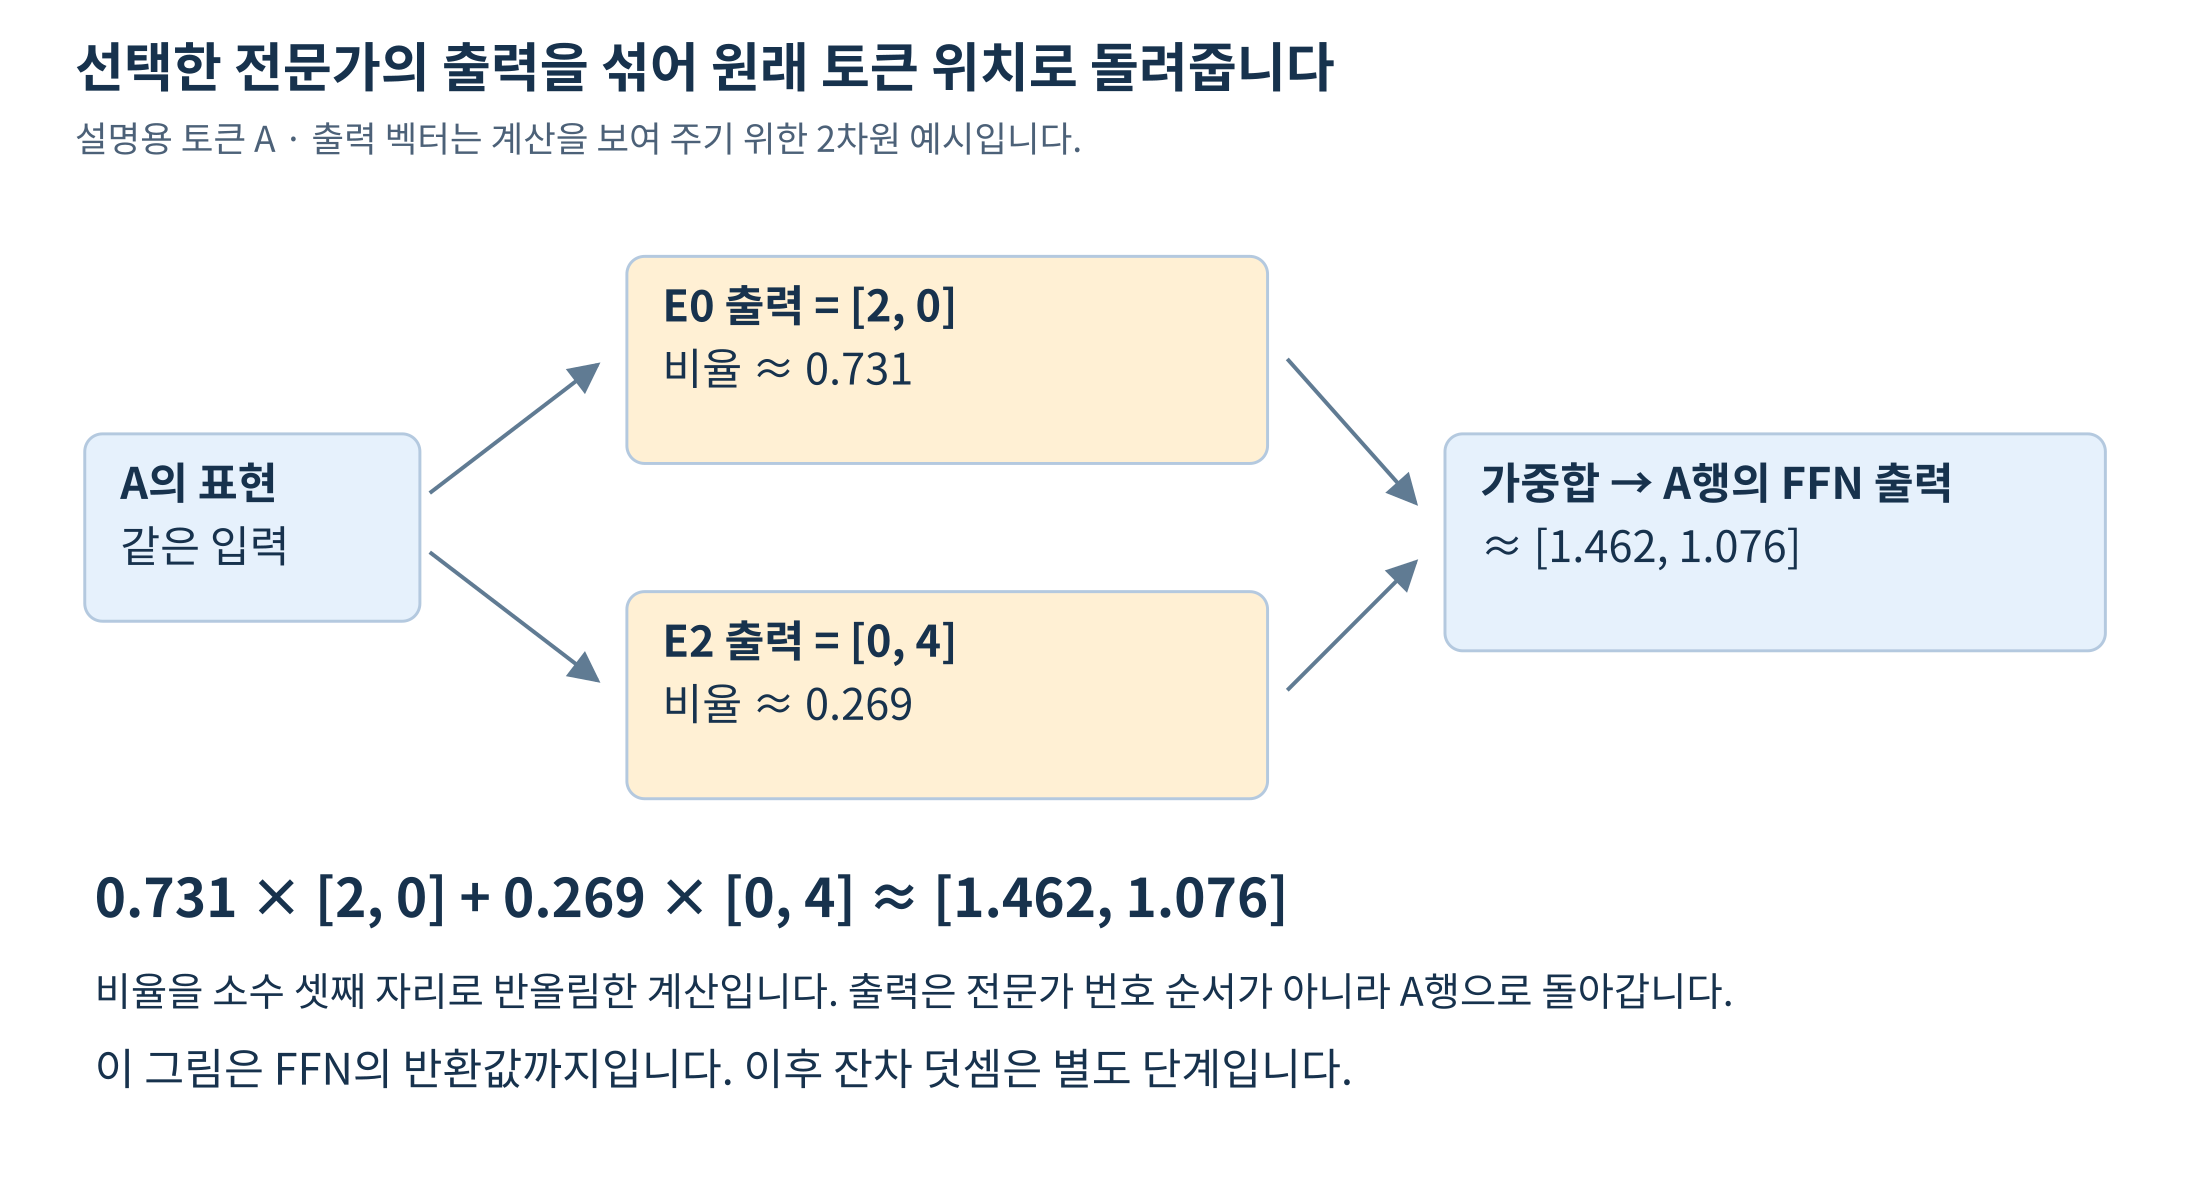

**그림 설명:** 두 출력은 이어 붙이지 않고 성분별 가중합합니다. 그림은 FFN의 반환값까지이며 이후 잔차 덧셈은 별도 단계입니다.


### 전문가 소스를 읽기 위한 연결

`hidden_states[token_idx]`는 해당 전문가가 처리할 토큰 행을 모읍니다. `weighted_output`은 전문가 출력에 토큰별 선택 가중치를 곱한 기여이며, `index_add_`는 그 기여를 원래 행에 누적합니다. 예시에서는 A의 두 기여를 더했지만, 실제 설정은 토큰마다 네 전문가를 선택합니다.

Dense의 `gate_proj`·`up_proj`·`down_proj`와 MoE의 라우터를 구별하면서, 블록의 `self_attn`과 `mlp`가 별도 모듈인지도 확인합니다. 출력되는 것은 이 구현의 소스 줄이며 실제 토큰 벡터나 라우팅 분포가 아닙니다.


### 코드 설명: 토큰 모으기 → 가중치 곱하기 → 원위치에 더하기

전문가 출력의 가중합과 Dense FFN의 고정 계산 경로를 비교합니다. 어텐션과 FFN이 별도 모듈이라는 점, Dense의 게이트와 전문가 라우터가 다르다는 점을 연결해 읽습니다.

한 토큰에 선택된 전문가가 여러 개면, 각 전문가의 출력을 해당 선택 가중치만큼 반영해 같은 토큰 위치에 합칩니다. Dense에서는 토큰마다 사용할 전문가를 따로 고르지 않고 같은 FFN을 적용합니다.


In [3]:
# 발췌문에서 token_idx는 토큰 행, top_k_pos는 선택 슬롯입니다. 한 토큰이 여러 전문가의 결과를 받을 수 있습니다.
expert_forward = method_text("GptOssExperts", "forward")
assert "routing_weights" in expert_forward and "index_add_" in expert_forward
# 토큰 선택·가중치 곱·원위치 누적 줄만 표시합니다. 전체 함수 실행이 아닙니다.
for line in expert_forward.splitlines():
    # any는 세 문구 중 하나라도 있는 줄을 고릅니다. index_add_는 같은 토큰 행의 기여를 덮어쓰지 않고 더합니다.
    if any(word in line for word in ("weighted_output =", "index_add_", "current_state =")):
        print(line.strip())
# 블록 생성자에서 self_attn과 mlp가 별도 모듈인지 확인합니다.
decoder_init = method_text("GptOssDecoderLayer", "__init__")
assert "self.self_attn = GptOssAttention" in decoder_init
assert "self.mlp = GptOssMLP" in decoder_init
print("Separate modules: self_attn and mlp")
llama_source = (base / "models/llama/modeling_llama.py").read_text(encoding="utf-8")
# Dense LlamaMLP의 함수 정의도 같은 AST 탐색으로 읽습니다.
llama_tree = ast.parse(llama_source)
llama_mlp = next(n for n in llama_tree.body if isinstance(n, ast.ClassDef) and n.name == "LlamaMLP")
llama_forward = next(n for n in llama_mlp.body if isinstance(n, ast.FunctionDef) and n.name == "forward")
# Dense의 gate_proj는 FFN 게이트이며 전문가를 고르는 MoE 라우터가 아닙니다.
dense_forward = ast.get_source_segment(llama_source, llama_forward)
assert "gate_proj" in dense_forward and "up_proj" in dense_forward and "down_proj" in dense_forward
# 이 Dense forward에는 전문가 top-k 선택이 없습니다. gate_proj는 FFN 게이트입니다.
assert "topk" not in dense_forward
print("Dense Llama MLP forward:", dense_forward)
print("[PASS] 실제 전문가 출력 가중합과 Dense FFN의 차이")

current_state = hidden_states[token_idx]
weighted_output = out * routing_weights[token_idx, top_k_pos, None]
next_states.index_add_(0, token_idx, weighted_output.to(hidden_states.dtype))
Separate modules: self_attn and mlp
Dense Llama MLP forward: def forward(self, x):
        down_proj = self.down_proj(self.act_fn(self.gate_proj(x)) * self.up_proj(x))
        return down_proj
[PASS] 실제 전문가 출력 가중합과 Dense FFN의 차이


### 출력 설명: 같은 토큰에 대한 여러 전문가의 기여를 더합니다

처음 세 줄은 **토큰을 골라 모으기 → 전문가 출력에 가중치 곱하기 → 원래 토큰 위치에 누적하기**라는 역할로 읽습니다. `token_idx`는 원래 토큰 위치이고 `top_k_pos`는 그 토큰이 선택한 전문가 슬롯입니다. 마지막 `None`은 가중치에 축을 하나 추가해 출력 벡터의 성분들에 같은 토큰별 가중치를 곱하도록 합니다.

`index_add_`가 보이는 이유는 여러 전문가의 결과를 같은 토큰 위치에 합쳐야 하기 때문입니다. 한 결과로 앞 결과를 덮어쓰는 것이 아닙니다. `Separate modules: self_attn and mlp`는 어텐션과 FFN이 별도 모듈임을 확인합니다. MoE가 어텐션 자체를 대신한다는 뜻이 아닙니다.

아래 Dense 함수에는 두 투영 결과를 원소별 곱한 뒤 `down_proj`로 되돌리는 계산이 있지만 전문가를 고르는 `topk`는 없습니다. **Dense에도 gate_proj라는 이름이 있을 수 있으므로 gate라는 단어만으로 MoE라고 판단하지 않습니다.** PASS는 이 구현 차이를 소스로 확인한 결과이며, 출력에 실제 전문가 벡터나 라우팅 가중치 수치는 없습니다.

## 4. 실제 행렬 shape로 전문가 파라미터 수 계산하기

**선택한 작업대 수와 보관할 설계도 수를 따로 셉니다.** 설명용 네 전문가가 각각 P개의 파라미터를 가진다면, 전문가 전체 저장분은 `4P`이고 A가 선택한 두 전문가 부분은 `2P`입니다. 선택되지 않은 E1·E3의 가중치가 사라진 것은 아닙니다. 다음 토큰에서 필요할 수 있습니다. 여기서 P는 이해를 위한 기호이며 실제 모델의 원소 수는 아래 설정과 선언으로 계산합니다.

전문가 하나에는 **gate와 up을 묶은 가중치**(`gate_up_proj`)와 그 편향(`gate_up_proj_bias`), **down projection 가중치**(`down_proj`)와 그 편향(`down_proj_bias`)이 있습니다. 역할로는 gate, up, down 세 가중치 행렬이 있지만, 구현은 gate와 up을 함께 저장하므로 가중치 텐서는 두 개입니다. `H`는 토큰 표현의 성분 수, `I`는 gate와 up 각각의 출력 성분 수입니다. 아래는 가중치 값을 계산하는 예가 아니라 **가중치와 편향을 몇 개 저장하는지 세는 예**입니다.

**설명용 예: 입력 2개(`H=2`), 내부 성분 3개(`I=3`)**

1. **gate와 up의 가중치: `H×2I = 2×6 = 12`개.** gate는 입력 성분 2개를 받아 출력 성분 3개를 만들고, up도 같은 입력으로 출력 3개를 만듭니다. 각 출력 성분에는 입력 성분마다 가중치가 하나씩, 즉 2개 필요합니다. 두 경로의 가중치를 한 행렬에 담으면 출력 열이 `3+3=6`개이므로 `2×6=12`개입니다.
2. **gate와 up의 편향: `2I = 6`개.** 각 출력 성분에는 가중합에 더하는 편향이 1개씩 있으므로 gate에 3개, up에 3개입니다. **첫 번째 묶음 투영은 6개 성분을 출력합니다.** 이 6개는 gate 쪽 3개와 up 쪽 3개입니다. 같은 위치에 대응하는 gate와 up을 한 쌍씩 결합하면 결과가 3개가 되며, **down projection에는 이 3개가 입력**됩니다.
3. **down projection의 가중치와 편향: `I×H = 3×2 = 6`개, `H = 2`개.** 내부 성분 3개를 다시 출력 성분 2개로 바꿉니다. 각 출력 성분에는 입력 3개에 대응하는 가중치 3개와 편향 1개가 필요하므로, 전체 가중치는 6개이고 편향은 2개입니다.

설명용 전문가 하나는 총 `12 + 6 + 6 + 2 = 26`개입니다.

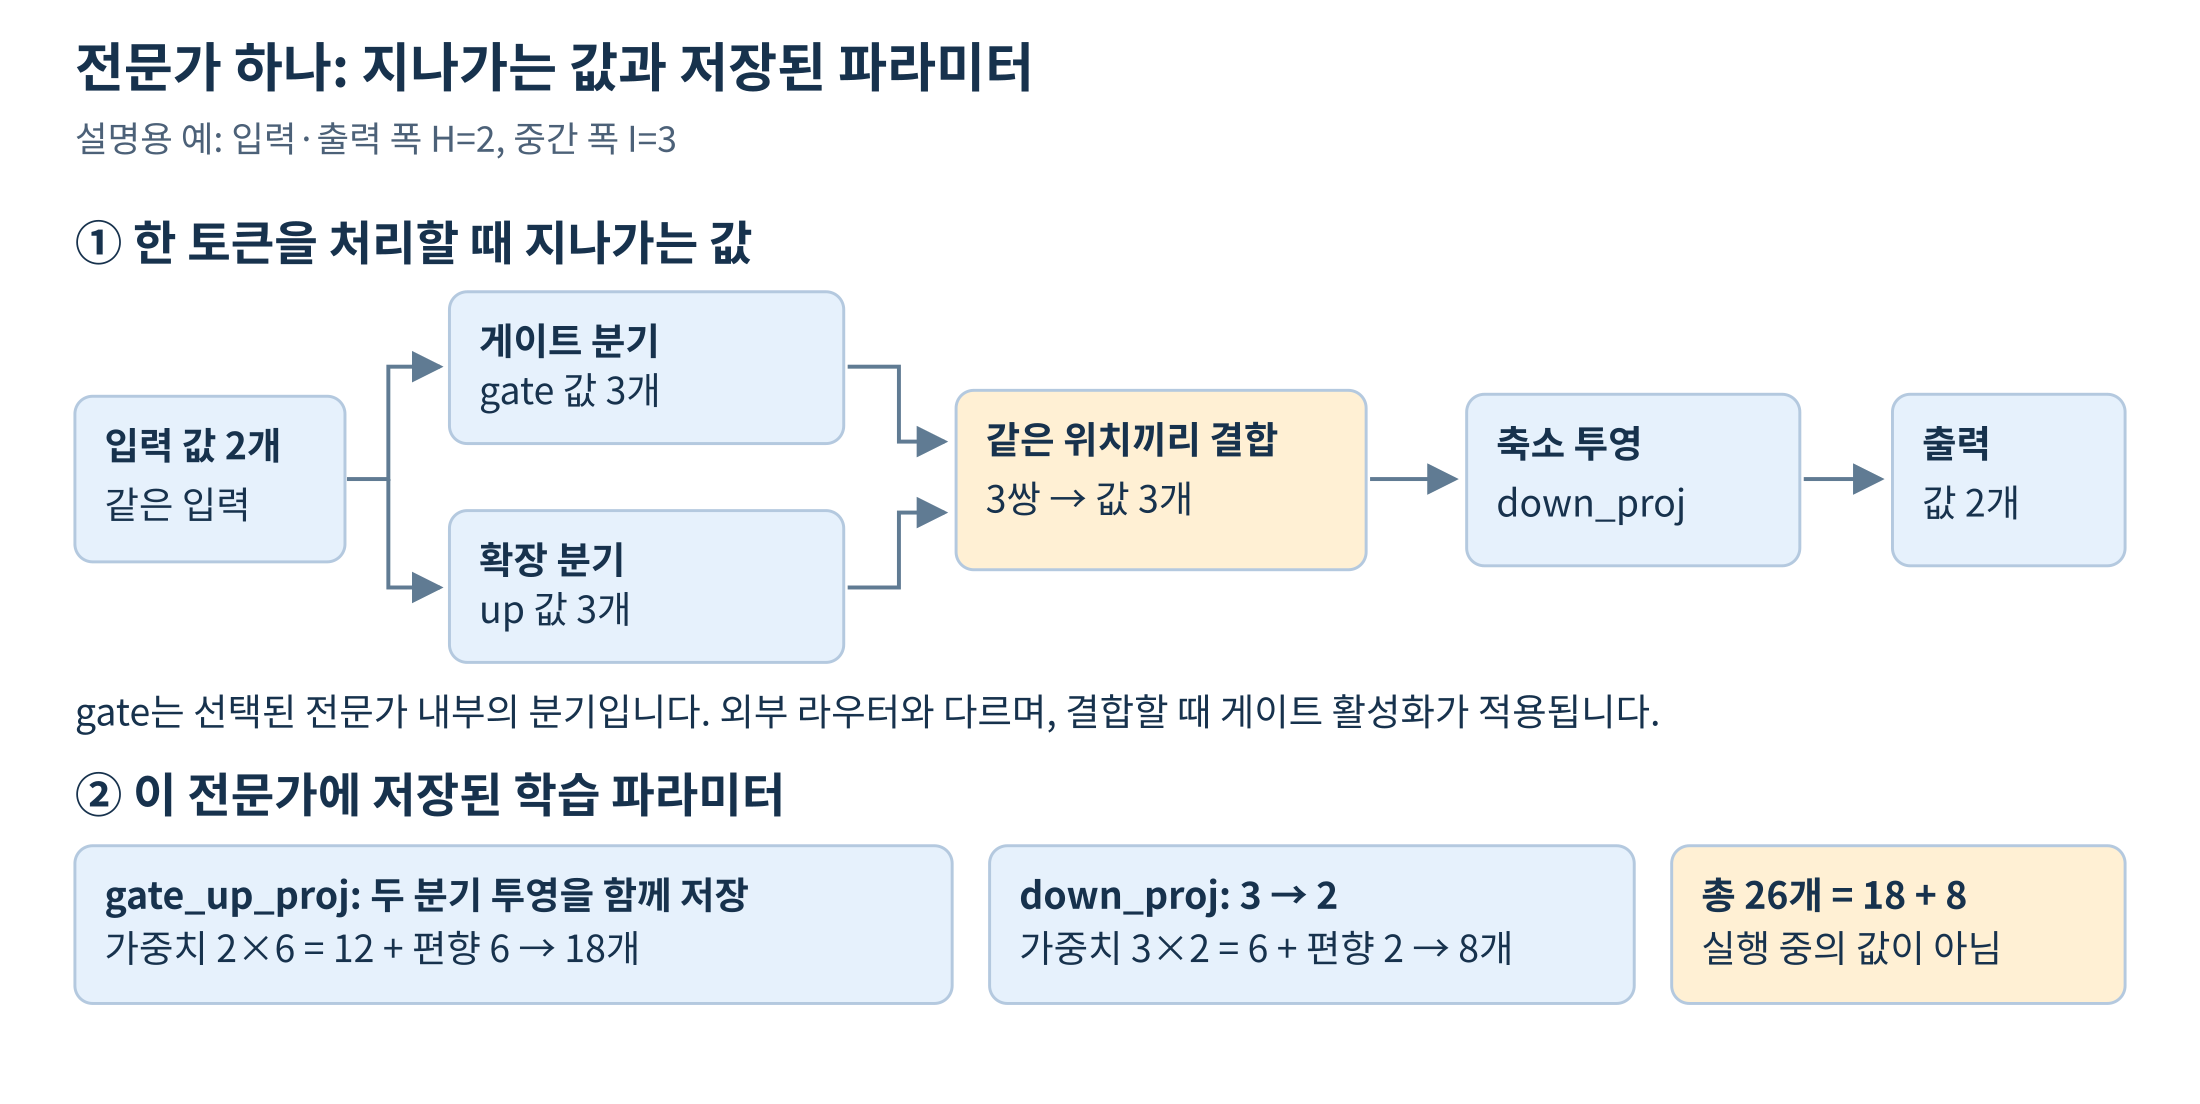

**그림 설명:** gate와 up의 출력 성분은 각각 3개지만, 같은 위치의 성분끼리 결합하므로 down projection에 들어가는 성분은 3개입니다. 그림의 26은 활성값이 아니라 학습할 가중치와 편향의 개수입니다.

실제 gpt-oss-20b에서 `H=I=2,880`이면 같은 순서로 `H×2I = 16,588,800`, `2I = 5,760`, `I×H = 8,294,400`, `H = 2,880`입니다. 따라서 `H×2I + I×H + 2I + H`를 계산하면 **전문가 하나에 24,891,840개**입니다.

gpt-oss-20b의 `H=2880`, `I=2880`을 넣은 뒤 후보 수 32를 곱하면 한 층의 전문가 저장분, 선택 수 4를 곱하면 토큰당 선택되는 전문가 부분입니다. 전문가 축 E가 있다는 것은 전문가마다 서로 다른 가중치 묶음이 있다는 뜻입니다. 라우터의 가중치는 후보 점수를 만드는 별도 묶음이므로 전문가 합계와 따로 셉니다.

아래에서는 실제 생성자의 행렬 shape를 읽어 원소 개수만 계산합니다. 선언문을 출력한다고 큰 텐서를 할당하는 것은 아니며, 아직 원소당 바이트를 곱하지 않았으므로 숫자의 단위는 **개**입니다.


### 전체 전문가 용량과 토큰당 선택량은 다릅니다
출력의 `nn.Parameter` 선언은 소스에서 찾아 표시한 줄입니다. 이 셀 자체가 그 거대한 텐서를 할당하는 것은 아닙니다. `H`는 입력 표현 폭, `I`는 전문가 내부 폭, `E`는 전문가 후보 수, `K`는 토큰당 선택 수입니다.

전문가 하나의 원소 수는 `gate_up_proj`와 `down_proj`의 가중치 원소 수에 각 편향의 원소 수를 더한 값입니다. 출력은 전문가 하나 24,891,840개, 한 층 전체 전문가 796,538,880개, 한 토큰이 선택하는 전문가 부분 99,567,360개입니다. 라우터 92,192개는 따로 계산합니다.

저장/선택 비율 `8.0`은 `32/4`에서 나온 **전문가 파라미터 개수의 비율**입니다. 전체 모델의 메모리가 1/8이 되거나 추론이 8배 빨라진다는 뜻이 아닙니다. `[PASS] 실제 shape 기반 전문가 부분 파라미터 산술`은 이 구분을 유지하며 산술을 확인하는 표시입니다.

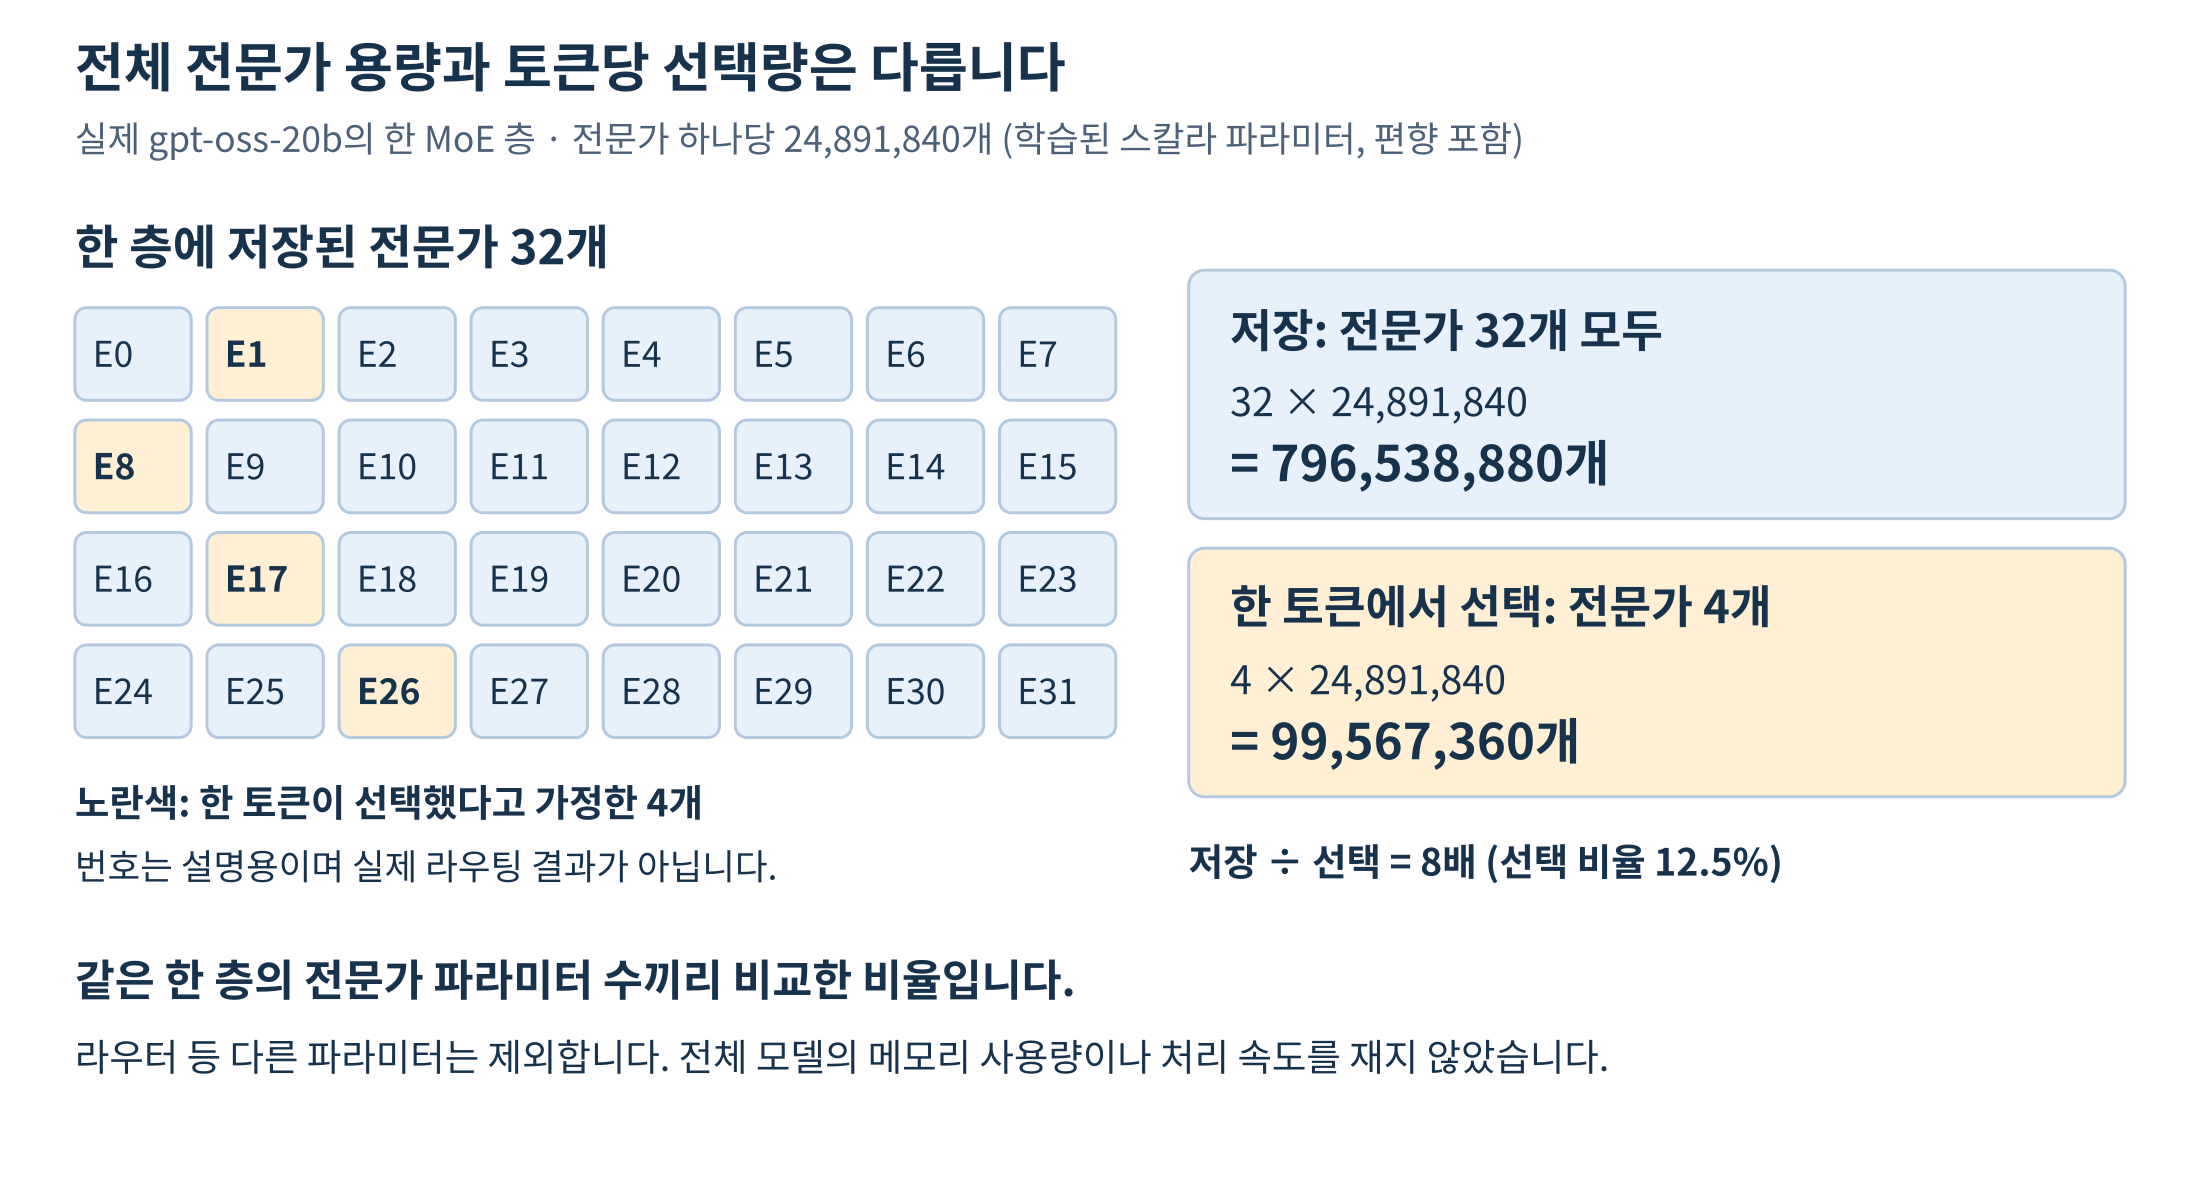

**그림 설명:** 한 층에서 전문가 32개 전체의 가중치·편향을 저장하지만, 토큰 하나의 전문가 FFN 계산에는 4개가 참여합니다. 수치는 전문가 부분의 파라미터 개수이며 바이트나 속도를 뜻하지 않습니다. 강조된 번호는 실제 토큰에서 측정한 선택 결과가 아닙니다.


### 코드 설명: 파라미터 선언의 각 축을 산술로 바꾸기

실제 파라미터 선언의 shape를 원소 개수로 바꾸어 전문가 하나·층별 저장분·토큰당 선택분을 구분합니다. 선언문을 읽을 뿐 큰 가중치 텐서를 생성하지 않습니다.

먼저 전문가 하나의 가중치와 편향 원소를 셉니다. 여기에 전체 전문가 수를 곱하면 한 층의 저장분, 선택된 전문가 수를 곱하면 토큰 하나에 대응하는 선택분입니다.


In [4]:
expert_init = method_text("GptOssExperts", "__init__")
# nn.Parameter 선언문을 표시할 뿐 해당 torch.empty 할당을 실행하지 않습니다.
for line in expert_init.splitlines():
    if "nn.Parameter" in line:
        print(line.strip())
# H는 표현 폭, I는 내부 폭, E는 후보 수, K는 토큰당 선택 수입니다.
# 선언 형상 (E,H,2I)·(E,I,H)의 E축은 전문가입니다. 2I는 게이트와 값 투영을 묶은 폭입니다.
H, I = config.hidden_size, config.intermediate_size
E, K = config.num_local_experts, config.num_experts_per_tok
# 두 투영의 가중치와 편향을 더한 전문가 하나의 스칼라 원소 수입니다.
# H×2I와 I×H는 행렬 원소 수, 2I와 H는 편향 수입니다. dtype 바이트를 곱하지 않았으므로 단위는 개입니다.
per_expert = H * (2 * I) + I * H + 2 * I + H
# 저장분은 E개, 한 토큰 선택분은 K개이며 둘 다 바이트가 아닌 원소 수입니다.
stored_per_layer = E * per_expert
selected_per_token_per_layer = K * per_expert
# 설정 튜플과 전문가 부분의 세 산술 결과를 각각 검사합니다.
assert (H, I, E, K) == (2880, 2880, 32, 4)
assert per_expert == 24891840
assert stored_per_layer == 796538880
assert selected_per_token_per_layer == 99567360
print("Expert parameters: one / stored per layer / selected per token per layer:",
      per_expert, stored_per_layer, selected_per_token_per_layer)
print("Stored / selected expert-only ratio:", E / K)
# 라우터 선형 가중치 E×H와 편향 E는 전문가 합계와 별도로 셉니다.
print("Router parameters per layer:", E * H + E)
print("[PASS] 실제 shape 기반 전문가 부분 파라미터 산술")

self.gate_up_proj = nn.Parameter(torch.empty(self.num_experts, self.hidden_size, 2 * self.intermediate_size))
self.gate_up_proj_bias = nn.Parameter(torch.empty(self.num_experts, 2 * self.intermediate_size))
self.down_proj = nn.Parameter(torch.empty((self.num_experts, self.intermediate_size, self.hidden_size)))
self.down_proj_bias = nn.Parameter(torch.empty(self.num_experts, self.hidden_size))
Expert parameters: one / stored per layer / selected per token per layer: 24891840 796538880 99567360
Stored / selected expert-only ratio: 8.0
Router parameters per layer: 92192
[PASS] 실제 shape 기반 전문가 부분 파라미터 산술


### 출력 설명: 선언된 shape를 원소 개수로 읽습니다

처음 네 줄은 실제 생성자에서 추출한 파라미터 선언입니다. 출력 순서대로 `gate_up_proj`는 `(E, H, 2I)`, `gate_up_proj_bias`는 `(E, 2I)`, `down_proj`는 `(E, I, H)`, `down_proj_bias`는 `(E, H)`입니다. 첫 축 `E`는 전문가 후보 32개를 뜻합니다. 나머지 축을 곱하면 전문가 하나에 필요한 원소 수를 구할 수 있으며, `H`와 `I`는 각각 2,880입니다. 이 선언문을 출력했을 뿐 텐서를 새로 할당한 것은 아닙니다.

산술 결과의 세 수는 순서대로 다음을 뜻합니다.

- **24,891,840:** 편향을 포함한 전문가 **하나**의 스칼라 원소 수입니다.
- **796,538,880:** 한 층에 저장된 전문가 **32개 전체**의 원소 수입니다.
- **99,567,360:** 한 토큰이 한 층에서 선택하는 전문가 **4개 부분**의 원소 수입니다.

저장/선택 비율 **8.0**은 32/4에서 나옵니다. 별도로 표시된 라우터 **92,192개**는 위 전문가 합계에 포함되지 않습니다. PASS는 실제 shape를 읽고 수행한 원소 수 산술이 맞았다는 뜻입니다. 숫자의 단위는 바이트가 아니며 8배 속도 향상이나 전체 메모리 1/8을 의미하지 않습니다.

## 5. 숫자가 말하지 않는 것을 구분하기

**토큰 하나가 두 곳만 골랐다고, 문장 전체가 두 곳만 쓴 것은 아닙니다.** 설명용 예시에서 A는 `{E0, E2}`, B는 `{E1, E2}`를 고르면 두 토큰이 사용한 전문가의 합집합은 `{E0, E1, E2}`로 세 개입니다. 토큰마다 선택 수는 두 개여도 여러 토큰을 함께 처리하면 서로 다른 후보가 더 많이 필요할 수 있습니다. 실제 GPT-OSS의 토큰당 4개도 배치 전체가 반드시 같은 4개만 쓴다는 뜻은 아닙니다.

**전문가 계산 이외의 일도 남습니다.** 작업대를 고르는 라우터, 토큰 간 문맥을 읽는 어텐션, 임베딩·정규화 등의 가중치와 연산은 앞 절의 전문가 합계 밖에 있습니다. 이들은 ‘공통으로 필요한 구성 요소’라는 뜻이며, 이 모델에 별도의 **공유 전문가(shared expert)**가 있다고 가정하는 것이 아닙니다. 선택된 전문가들을 서로 다른 장치에서 계산한다면 토큰 전달·결과 수집의 통신 비용도 생길 수 있습니다.

실제 후보 32개 중 4개는 12.5%입니다. 이 값은 **한 토큰의 한 층에서 선택하는 전문가 비율**이지 전체 모델 저장량·속도 비율이 아닙니다. 모델 전체 메모리가 1/8로 줄거나 실행이 8배 빨라진다고 결론 내릴 수 없습니다. 가중치 저장 형식·양자화, 배치, 장치 배치와 커널에 따라 실제 비용은 달라집니다.

이제 앞 절의 전문가 부분 원소 수를 24층으로 합산합니다. 각 층에는 별도의 전문가 가중치가 있으므로 층별 저장분을 더하며, 매 층에서 같은 전문가 번호를 선택한다고 가정할 필요는 없습니다. 출력의 `expert-only`는 이 합계가 **전문가 부분만** 포함한다는 경계입니다. 실제 품질·지연시간·VRAM·전문가 이용률은 이번 실습에서 측정하지 않습니다.


### MoE의 장점을 설명하되 측정하지 않은 성능은 단정하지 않기
앞 셀의 전문가 원소 수에 24층을 곱하면 전체 전문가 부분은 19,116,933,120개, 토큰당 선택되는 전문가 부분의 층별 합은 2,389,616,640개입니다. `0.125`는 각 층에서 후보 32개 중 4개를 선택하는 비율입니다. 모든 층에서 같은 전문가 번호를 고른다는 뜻은 아닙니다.

MoE는 토큰당 계산에 참여하는 전문가 수를 제한하면서 전체 전문가 용량을 늘리려는 설계입니다. 대신 전체 가중치 저장, 라우팅, 전문가 간 부하 불균형 및 분산 실행 시 통신 등의 비용을 고려해야 합니다. 여기의 합계는 **전문가 부분만** 포함하며 어텐션·임베딩·정규화·라우터 등을 포함한 모델 전체 파라미터 수가 아닙니다.

`Not measured` 줄처럼 실제 전문가 번호·확률, 품질, 지연시간, VRAM 사용량은 측정하지 않았습니다. 마지막 `[PASS] Lesson 07 분석 완료`는 산술·소스 분석 완료를 뜻합니다.

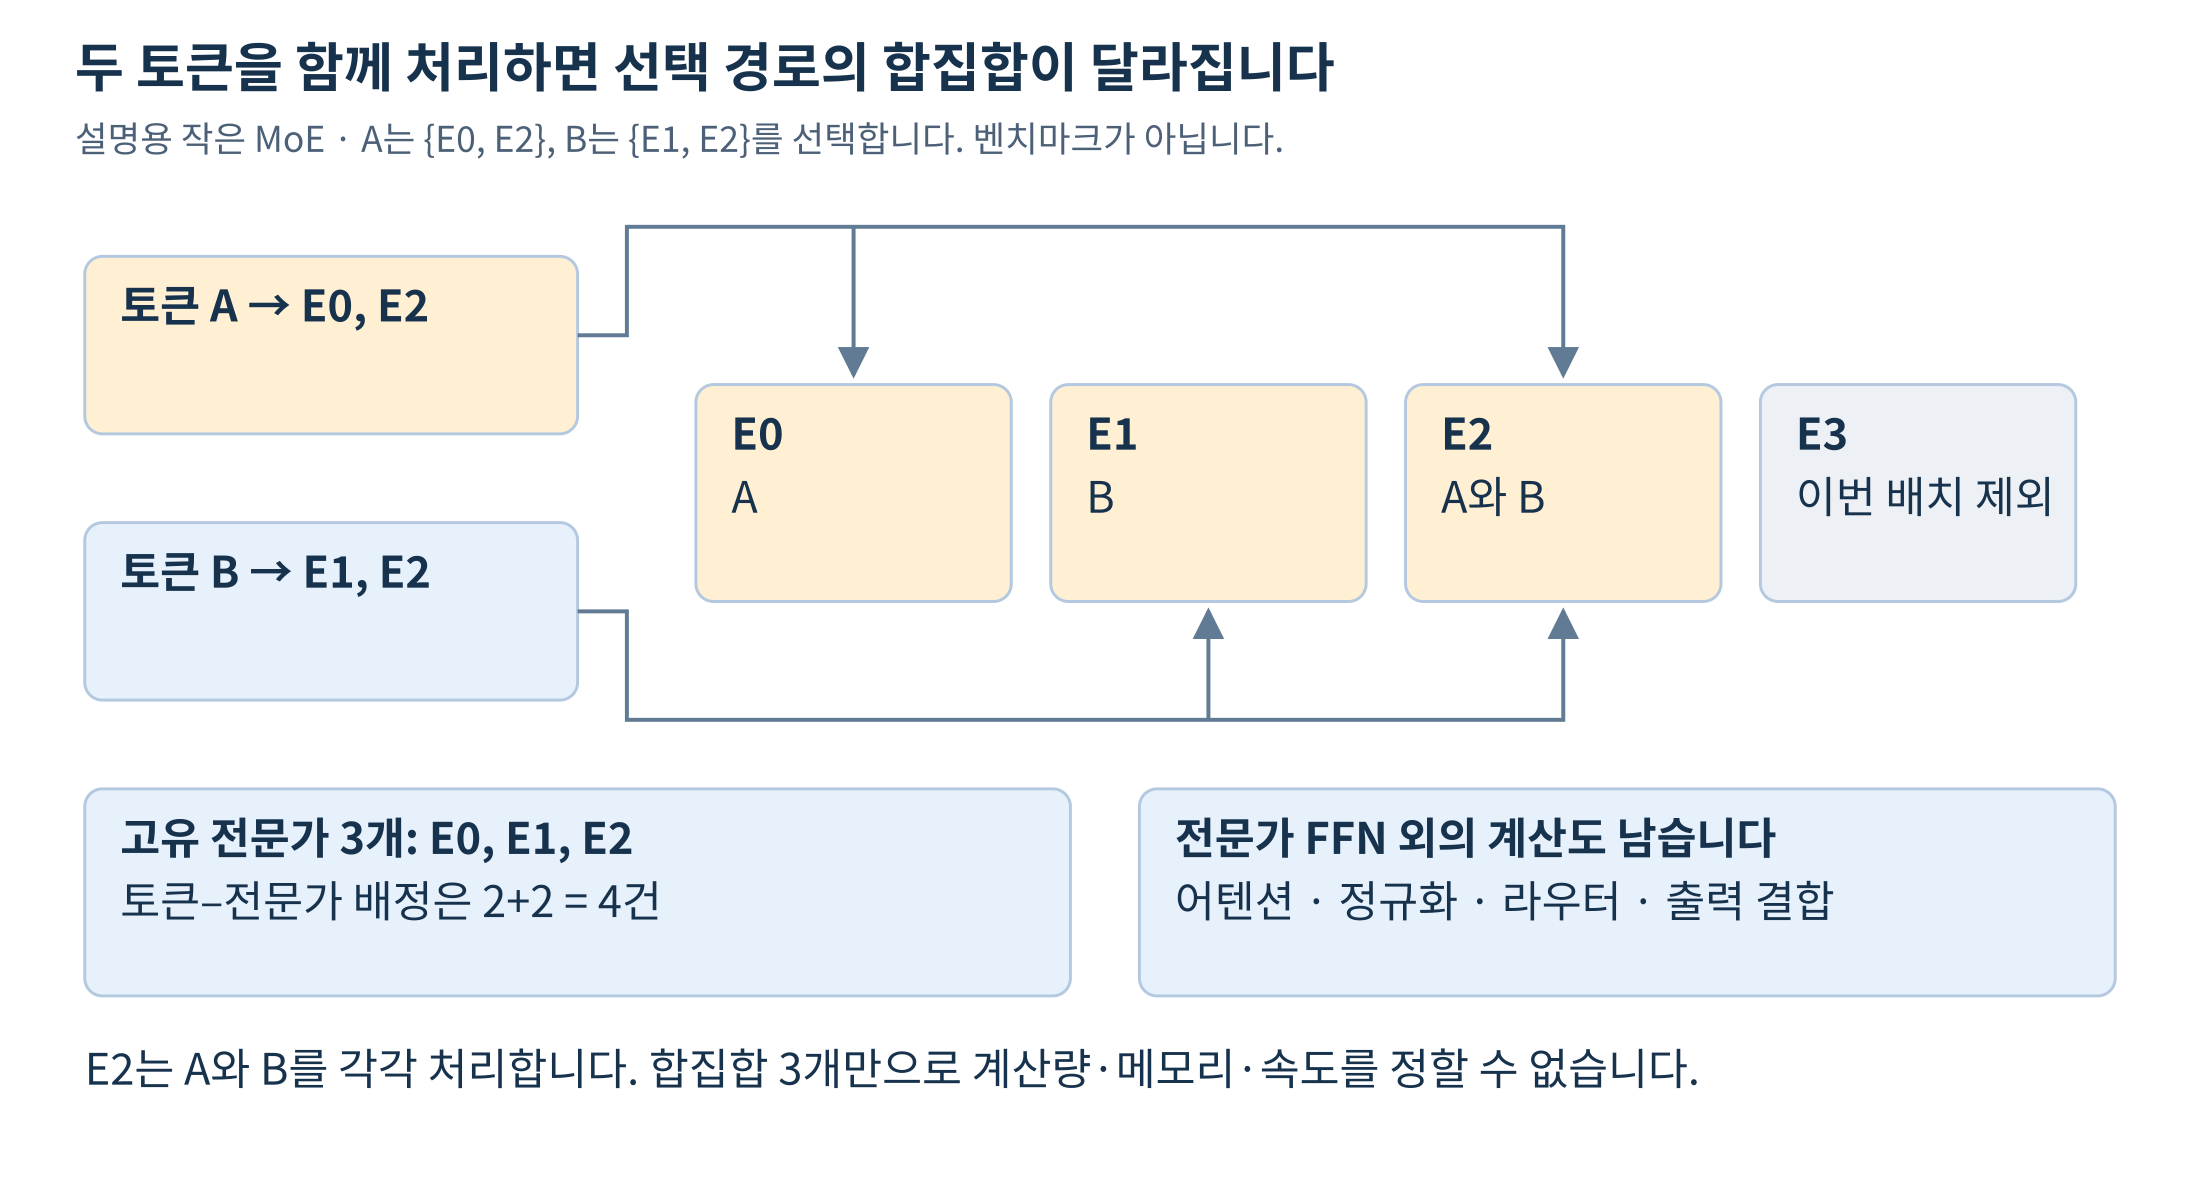

**그림 설명:** E2는 A와 B를 따로 처리합니다. 고유 전문가 수, 토큰별 선택 수, 전체 계산 비용은 같은 양이 아닙니다. 라우터·출력 결합과 어텐션 등의 비용도 남습니다.


### 코드 설명: 층별 합계를 전체 블록에 확장하기

층별 전문가 부분의 산술을 24층으로 확장합니다. 합계의 범위는 전문가 부분이며, 전체 모델 크기나 실제 추론 속도를 측정한 것은 아닙니다.

앞에서 구한 층당 두 수치에 각각 층 수를 곱합니다. 하나는 모든 층에 저장되는 전문가 부분이고, 다른 하나는 토큰 하나가 각 층에서 선택하는 전문가 부분의 합입니다.


In [5]:
# 전문가 부분만 합산하며 어텐션·임베딩·라우터 등은 포함하지 않습니다.
stored_expert_total = stored_per_layer * config.num_hidden_layers
# 한 토큰의 층별 선택분을 합하며 모든 층에서 같은 전문가 번호를 고른다는 뜻은 아닙니다.
# 토큰마다 선택되는 전문가가 달라도 각 층에서 K개씩 쓰는 구조는 같으므로 층 수를 곱할 수 있습니다.
selected_expert_total_per_token = selected_per_token_per_layer * config.num_hidden_layers
# 전문가 부분의 전 층 저장분과 토큰당 선택분 산술을 각각 확인합니다.
assert stored_expert_total == 19116933120
assert selected_expert_total_per_token == 2389616640
print("All-layer expert-only stored scalar count:", stored_expert_total)
print("Per-token selected expert-only scalar count across layers:", selected_expert_total_per_token)
# K/E는 설정상의 선택 비율이지 데이터 전체에서 관찰한 전문가 이용률이 아닙니다.
print("Per-layer selected expert fraction:", K / E)
print("Not measured: router IDs/probabilities, output quality, latency, VRAM")
print("[PASS] 전문가 부분과 전체 모델·성능 주장 구분")
print("[PASS] Lesson 07 분석 완료")

All-layer expert-only stored scalar count: 19116933120
Per-token selected expert-only scalar count across layers: 2389616640
Per-layer selected expert fraction: 0.125
Not measured: router IDs/probabilities, output quality, latency, VRAM
[PASS] 전문가 부분과 전체 모델·성능 주장 구분
[PASS] Lesson 07 분석 완료


### 출력 설명: ‘전체’의 범위는 전문가 부분의 24층 합계입니다

**19,116,933,120개**는 앞 셀의 한 층 저장분에 24층을 곱한 전문가 전체 원소 수입니다. **2,389,616,640개**는 한 토큰이 각 층에서 선택하는 전문가 부분을 24층에 걸쳐 합한 값입니다. 두 값 모두 스칼라 개수이며 어텐션·임베딩·정규화·라우터를 포함한 모델 전체 파라미터 수가 아닙니다.

선택 비율 **0.125 = 12.5%**는 한 층의 후보 32개 중 4개를 고른다는 설정을 표현합니다. 실제 입력 데이터에서 관찰한 전문가 이용률이 아니며, 모든 층이나 모든 토큰이 동일한 네 전문가를 고른다는 뜻도 아닙니다.

`Not measured`에는 라우터 ID·확률, 출력 품질, 지연시간, VRAM이 명시되어 있습니다. 이는 숫자로 확인한 범위를 넘어 성능 결론을 내리지 않도록 하는 경계입니다. 두 PASS는 전문가 부분의 산술과 분석 완료 표시이며, 대형 모델의 실제 추론 성공으로 읽지 않습니다.

## 6. 한 장으로 정리하는 gpt-oss-20b 전체 구조

제6교시는 **어텐션이 어느 위치를 읽는지**, 제7교시는 **한 토큰에 어느 FFN을 적용하는지** 살펴봤습니다. 실제 gpt-oss-20b에서는 한 디코더 블록 안의 서로 다른 단계에서 두 선택이 일어납니다. 아래 그림의 큰 흐름을 먼저 보고, 오른쪽 확대에서 한 블록을 따라가 보세요.

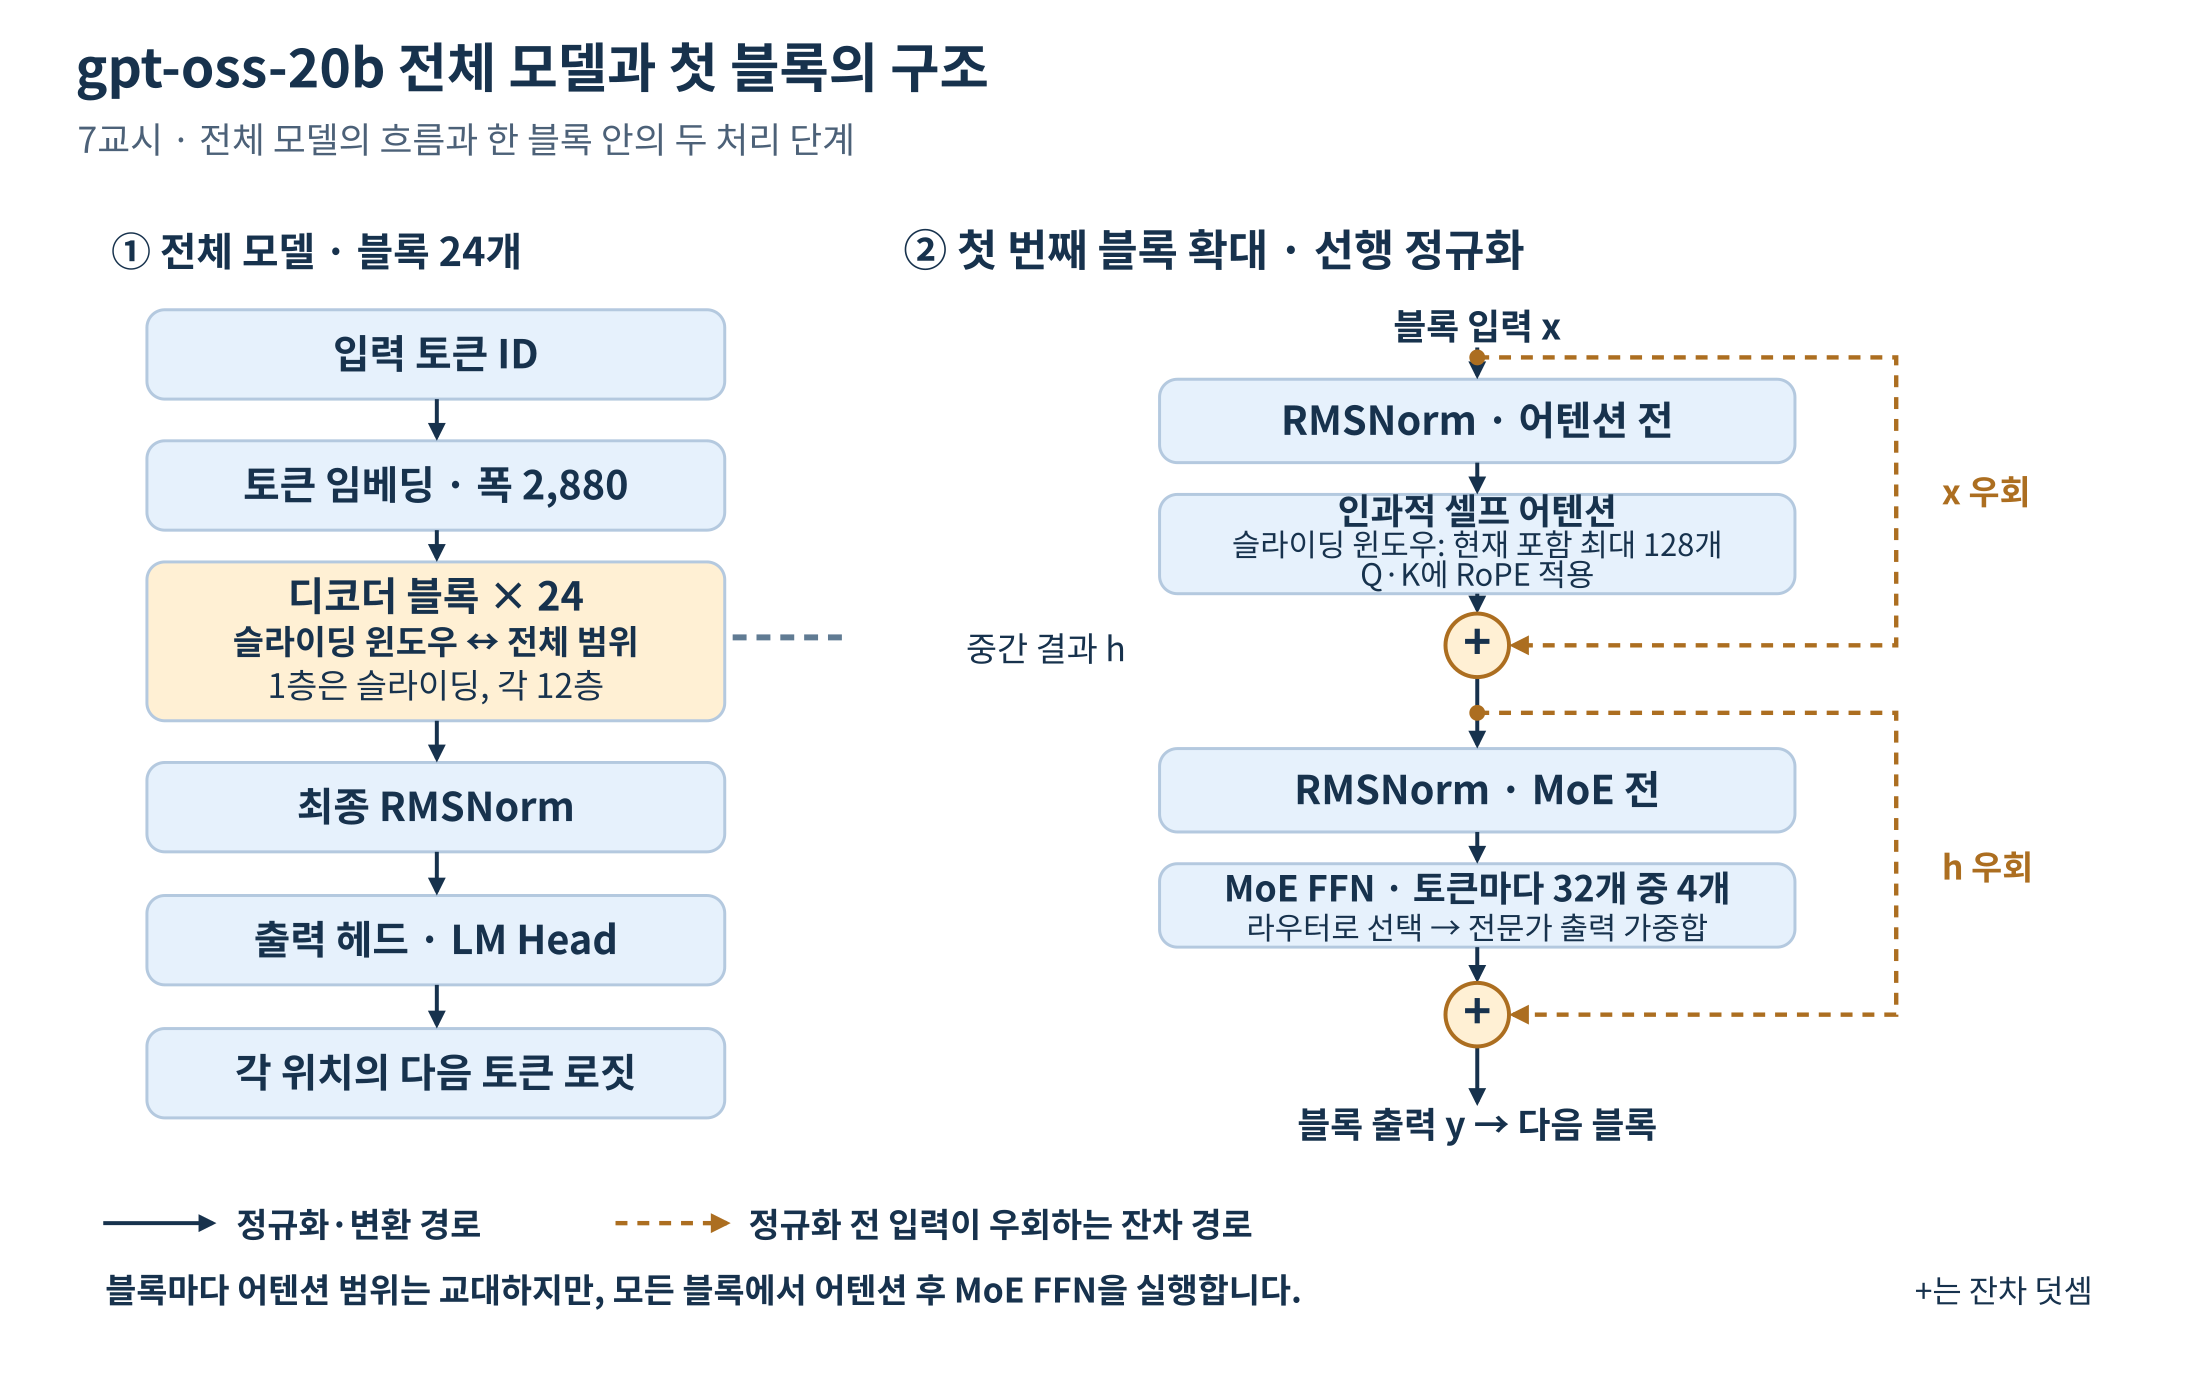

**그림 설명:** 전체 모델의 입출력과 디코더 블록 하나의 처리 순서를 보여 주는 구조도입니다. 점선 잔차 화살표는 각 단계의 정규화 전 표현을 보존해 그 단계의 처리 결과에 더하는 경로입니다. 이 그림은 설정과 구현을 읽어 구성했으며 모델을 실행하여 얻은 출력은 아닙니다.

1. **토큰 ID → 임베딩 → 디코더 블록 24개.** 입력 토큰 ID마다 학습된 임베딩에서 2,880개 성분의 벡터를 가져옵니다. 1층은 슬라이딩 윈도우 인과적 셀프 어텐션, 2층은 전체 범위 인과적 셀프 어텐션이며 24층까지 번갈아 12개씩 배치합니다. 슬라이딩 윈도우 층은 현재 위치를 포함해 최대 128개 위치, 전체 범위 층은 현재와 이전의 모든 허용 위치를 직접 참고합니다. 두 방식 모두 미래 토큰은 읽지 않습니다. 예를 들어 0부터 센 위치 128에서는 1층이 1~128을, 2층이 0~128을 직접 참고합니다. 두 층 모두 어텐션 다음에 MoE FFN을 실행합니다.
2. **블록 내부 → 어텐션과 MoE는 순서대로 실행됩니다.** 블록 입력에 RMSNorm을 적용한 뒤 해당 층의 인과적 셀프 어텐션을 실행하고, 그 결과에 정규화 전 블록 입력을 더합니다. 이렇게 얻은 표현을 다시 RMSNorm으로 정규화한 뒤 MoE FFN에 넣습니다. 라우터가 토큰마다 그 층의 전문가 32개 중 4개를 선택하고, 선택한 점수로 구한 가중치로 전문가 출력을 가중합합니다. 여기에 MoE 직전 정규화 전 표현(첫 잔차 덧셈의 결과)을 더하면 블록 출력입니다. **어텐션과 MoE 중 하나만 고르는 것이 아닙니다.** 층별로 바뀌는 것은 어텐션의 직접 참고 범위이고, 토큰별로 바뀔 수 있는 것은 FFN 전문가 조합입니다.
3. **마지막 블록 → 최종 RMSNorm → LM Head → 다음 토큰 로짓.** 24개 블록을 지난 표현을 한 번 더 정규화하고, LM Head(출력 투영층)가 다음 토큰 후보마다 점수를 만듭니다. 이 로짓은 어휘 후보의 점수로, 블록 내부에서 라우터가 계산한 **전문가 후보 점수**와는 대상이 다릅니다. 문장을 이어 생성할 때는 마지막 위치의 로짓을 사용해 다음 토큰을 고릅니다. 점수를 계산하는 것과 그 점수로 토큰을 선택하는 것은 별도 단계입니다.

앞 교시와 연결하면, 두 종류의 어텐션은 모두 GQA(쿼리 헤드 64개, 키·값 헤드 각각 8개)를 사용하고, RoPE로 쿼리와 키에 위치 정보를 반영합니다. 그림에서는 블록의 큰 순서를 읽기 쉽도록 두 기법의 세부 계산을 생략했습니다.

**설정과 학습값을 구별하세요.** 표현 폭 2,880, 블록 수 24, 어텐션의 교대 순서와 윈도우 크기, 전문가 후보 32개와 토큰당 선택 4개는 이 체크포인트의 설정입니다. 임베딩, 어텐션 투영, 라우터의 가중치·편향, 전문가 FFN, 정규화의 스케일, LM Head 등의 수치는 학습값입니다. 추론에서는 이 파라미터를 고정해 사용하더라도 입력 표현에 따라 전문가 선택은 달라질 수 있습니다. 이번 교시에서는 가중치를 불러오거나 추론하지 않았습니다.

그림의 수치는 [gpt-oss-20b 고정 공개 설정](https://huggingface.co/openai/gpt-oss-20b/blob/6cee5e81ee83917806bbde320786a8fb61efebee/config.json)을, 처리 순서는 [Transformers v5.23.0 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/gpt_oss/modeling_gpt_oss.py)에서 `GptOssDecoderLayer`, `GptOssModel`, `GptOssForCausalLM`을 참고했습니다.


## 정리와 자기 점검

- [ ] 전문가 32개 중 4개를 선택한다고 나머지 가중치를 저장하지 않아도 되나요?

  **핵심 답:** 아닙니다. 토큰당 선택은 계산에 참여할 경로를 고르는 것이지 후보 가중치를 삭제하는 규칙이 아닙니다.

  **이유:** 다른 토큰이 나머지 전문가를 선택할 수 있으므로 전체 후보의 가중치를 사용할 수 있어야 합니다. 실제 배치는 분산이나 오프로딩을 사용할 수 있지만, 그 방법을 이 설정만으로 결정할 수는 없습니다.

- [ ] 전문가 부분 선택량을 전체 모델 활성 파라미터나 속도 향상 배수로 부를 수 없는 이유는 무엇인가요?

  **핵심 답:** 이 계산에는 전문가 부분만 포함되어 있고, 어텐션·임베딩·정규화·라우터 등은 빠져 있습니다. 또한 원소 수 비율은 실행 시간 비율이 아닙니다.

  **이유:** 32/4=8은 후보 전문가 저장분과 토큰당 선택분의 비율입니다. 실제 속도에는 라우팅, 메모리 접근, 장치 간 통신, 구현 및 배치 조건도 영향을 주므로 별도 측정이 필요합니다.


## 참고 자료
- Fedus 외, [Switch Transformers §2.1: 토큰 라우팅](https://arxiv.org/html/2101.03961#S2.SS1): Dense와 sparse expert routing의 개념. Switch의 top-1과 이번 GPT-OSS의 top-4를 구분합니다.
- OpenAI, [gpt-oss Model Card §2.2: Architecture](https://arxiv.org/html/2508.10925#S2.SS2): 실제 20b 모델의 전문가 설계. 이번 산술은 전문가 부분만의 수입니다.
- [공식 GPT-OSS 설정](https://huggingface.co/openai/gpt-oss-20b/blob/6cee5e81ee83917806bbde320786a8fb61efebee/config.json), [SmolLM2 설정](https://huggingface.co/HuggingFaceTB/SmolLM2-135M/blob/93efa2f097d58c2a74874c7e644dbc9b0cee75a2/config.json).
- [Transformers v5.23.0 GPT-OSS 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/gpt_oss/modeling_gpt_oss.py), [Llama MLP 구현](https://github.com/huggingface/transformers/blob/v5.23.0/src/transformers/models/llama/modeling_llama.py#L152-L171). 실제 설치 소스는 셀에서 직접 읽고 해시를 출력합니다.
- 설정 출처의 라이선스: [GPT-OSS Apache 2.0](https://huggingface.co/openai/gpt-oss-20b/blob/6cee5e81ee83917806bbde320786a8fb61efebee/LICENSE), [SmolLM2 공식 모델 카드: Apache 2.0](https://huggingface.co/HuggingFaceTB/SmolLM2-135M).